# Análisis EDA + Modelado — Fuga de clientes (Churn)
Universidad del Pacífico

La numeración de las secciones corresponde a los apartados del enunciado.

> **Nota de esta versión.** Las secciones 0 a 8 son el taller guiado de EDA tal como se
> trabajó en clase (comprensión → limpieza → exploración → bivariado → correlaciones → insights).
> A partir de la sección 9 se agrega lo que faltaba: preparar los datos con **one-hot encoding**
> real (no solo para un heatmap, sino para alimentar un modelo) y entrenar y evaluar los tres
> algoritmos de clasificación vistos en clase, siguiendo el mismo estándar de evaluación
> train-vs-test del caso de la Sesión 5 (Vitrina).

## 0. Preparación del entorno

In [1]:
!pip install ydata-profiling missingno -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 72.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.9 MB/s eta 0:00:00


In [2]:
import numpy as np                  # álgebra lineal
import pandas as pd                 # manejo de datos
import seaborn as sns               # gráficos
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick   # formato de ejes
import missingno as msno            # visualización de nulos
import math

from collections import Counter
from ydata_profiling import ProfileReport

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

/tmp/ipykernel_2927/1384970484.py:10: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## 1. Comprensión de datos

Estructura de la tabla, dimensiones, tipos de variables y variable objetivo.

In [3]:
RUTA = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # ajustar según dónde esté el archivo

df = pd.read_csv(RUTA)
df.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [4]:
df.tail(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.columns.values

array(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
       'TotalCharges', 'Churn'], dtype=object)

In [6]:
df.shape

(7043, 21)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [9]:
# Variable objetivo
df["Churn"].value_counts(normalize=True).round(4) * 100

,proportion
Churn,
No,73.46
Yes,26.54


### 1.1 Perfilado automático

In [10]:
ProfileReport(df)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
%matplotlib inline
# ProfileReport de la celda anterior desconecta el hook de renderizado inline de matplotlib;
# esta línea lo reactiva para que todos los gráficos de aquí en adelante se muestren.

## 2. Limpieza inicial

### 2.1 Conversión de tipos
`TotalCharges` llega como texto y debe convertirse a numérica.

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


### 2.2 Identificación de valores nulos

In [12]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [13]:
# Porcentaje de nulos por columna
(df.isnull().sum() / len(df)) * 100

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


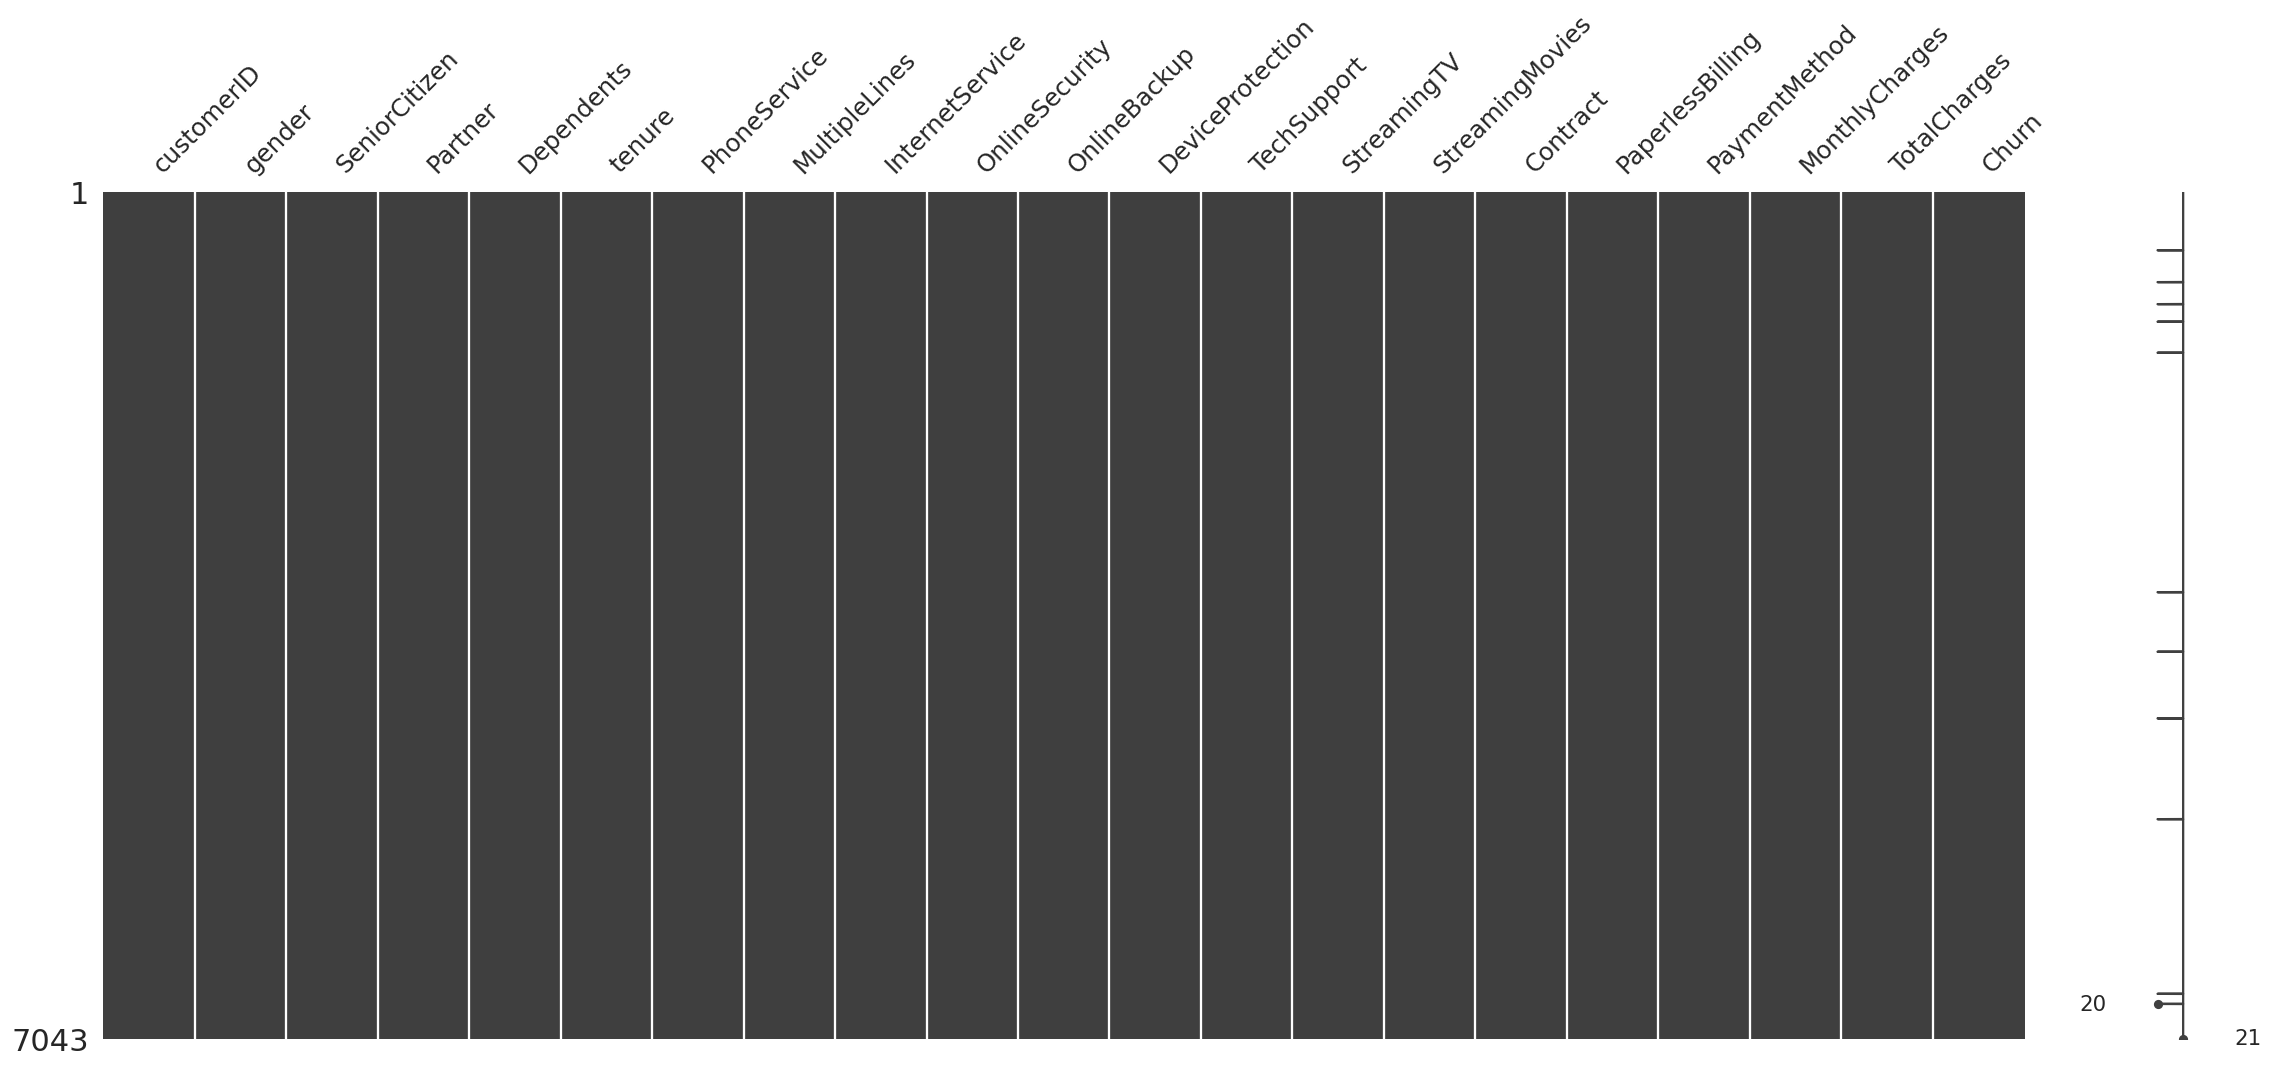

In [14]:
# Matriz de valores faltantes
msno.matrix(df);

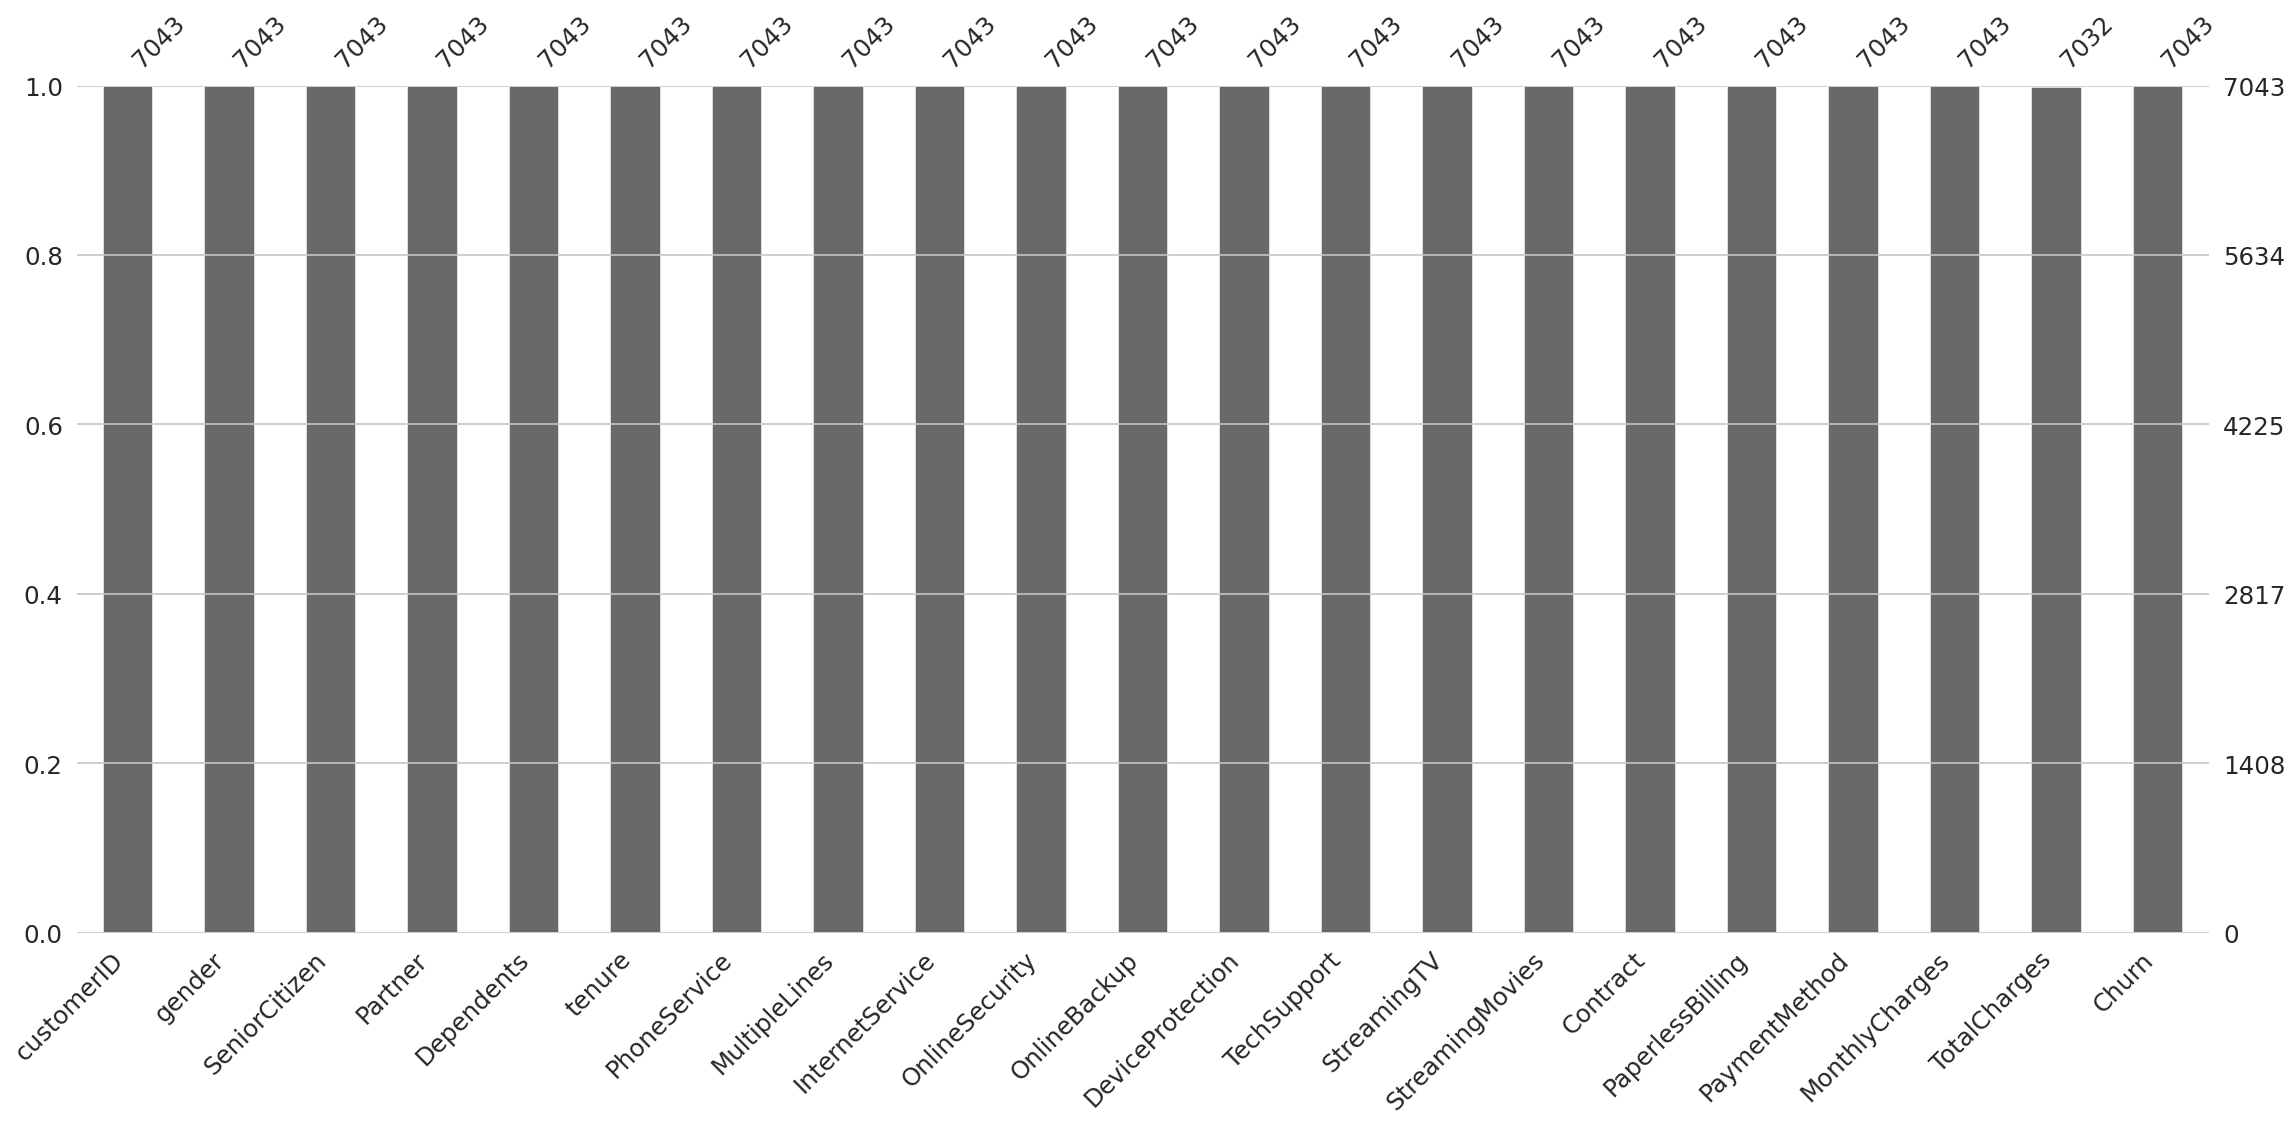

In [15]:
# Barras de valores faltantes
msno.bar(df=df);

In [16]:
# ¿Qué tienen en común los registros con TotalCharges nulo?
df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### 2.3 Tratamiento y preparación

In [17]:
# Eliminación de los valores faltantes
df.dropna(inplace=True)

# Se retira el ID del cliente para el análisis
df2 = df.iloc[:, 1:]

# Variable objetivo a binaria
df2["Churn"] = df2["Churn"].map({"Yes": 1, "No": 0})

df2.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [18]:
(df2.isnull().sum() / len(df2)) * 100

,0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0
OnlineBackup,0.0


### 2.4 Análisis de valores duplicados

In [19]:
# ¿Son clientes repetidos o clientes distintos con el mismo perfil?
print("Duplicados con customerID: ", df.duplicated().sum())
print("customerID únicos:         ", df["customerID"].nunique(), "de", len(df))
print("Duplicados sin customerID: ", df2.duplicated().sum())

Duplicados con customerID:  0
customerID únicos:          7032 de 7032
Duplicados sin customerID:  22


In [20]:
df2.drop_duplicates(inplace=True)
df2.shape

(7010, 20)

## 3. Exploración de variables categóricas

In [21]:
df2.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [22]:
columnsString = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
                 'PaperlessBilling', 'PaymentMethod', 'Churn']

In [23]:
for x in columnsString:
    frecuencias = df2[x].value_counts(dropna=False)
    porcentajes = (frecuencias / len(df2)) * 100
    print(x)
    print(pd.DataFrame({"Frecuencia": frecuencias, "Porcentaje (%)": porcentajes}).round(2))
    print("\n")

gender
        Frecuencia  Porcentaje (%)
gender                            
Male          3535           50.43
Female        3475           49.57


Partner
         Frecuencia  Porcentaje (%)
Partner                            
No             3617            51.6
Yes            3393            48.4


Dependents
            Frecuencia  Porcentaje (%)
Dependents                            
No                4911           70.06
Yes               2099           29.94


PhoneService
              Frecuencia  Porcentaje (%)
PhoneService                            
Yes                 6330            90.3
No                   680             9.7


MultipleLines
                  Frecuencia  Porcentaje (%)
MultipleLines                               
No                      3363           47.97
Yes                     2967           42.33
No phone service         680            9.70


InternetService
                 Frecuencia  Porcentaje (%)
InternetService                            
Fibe

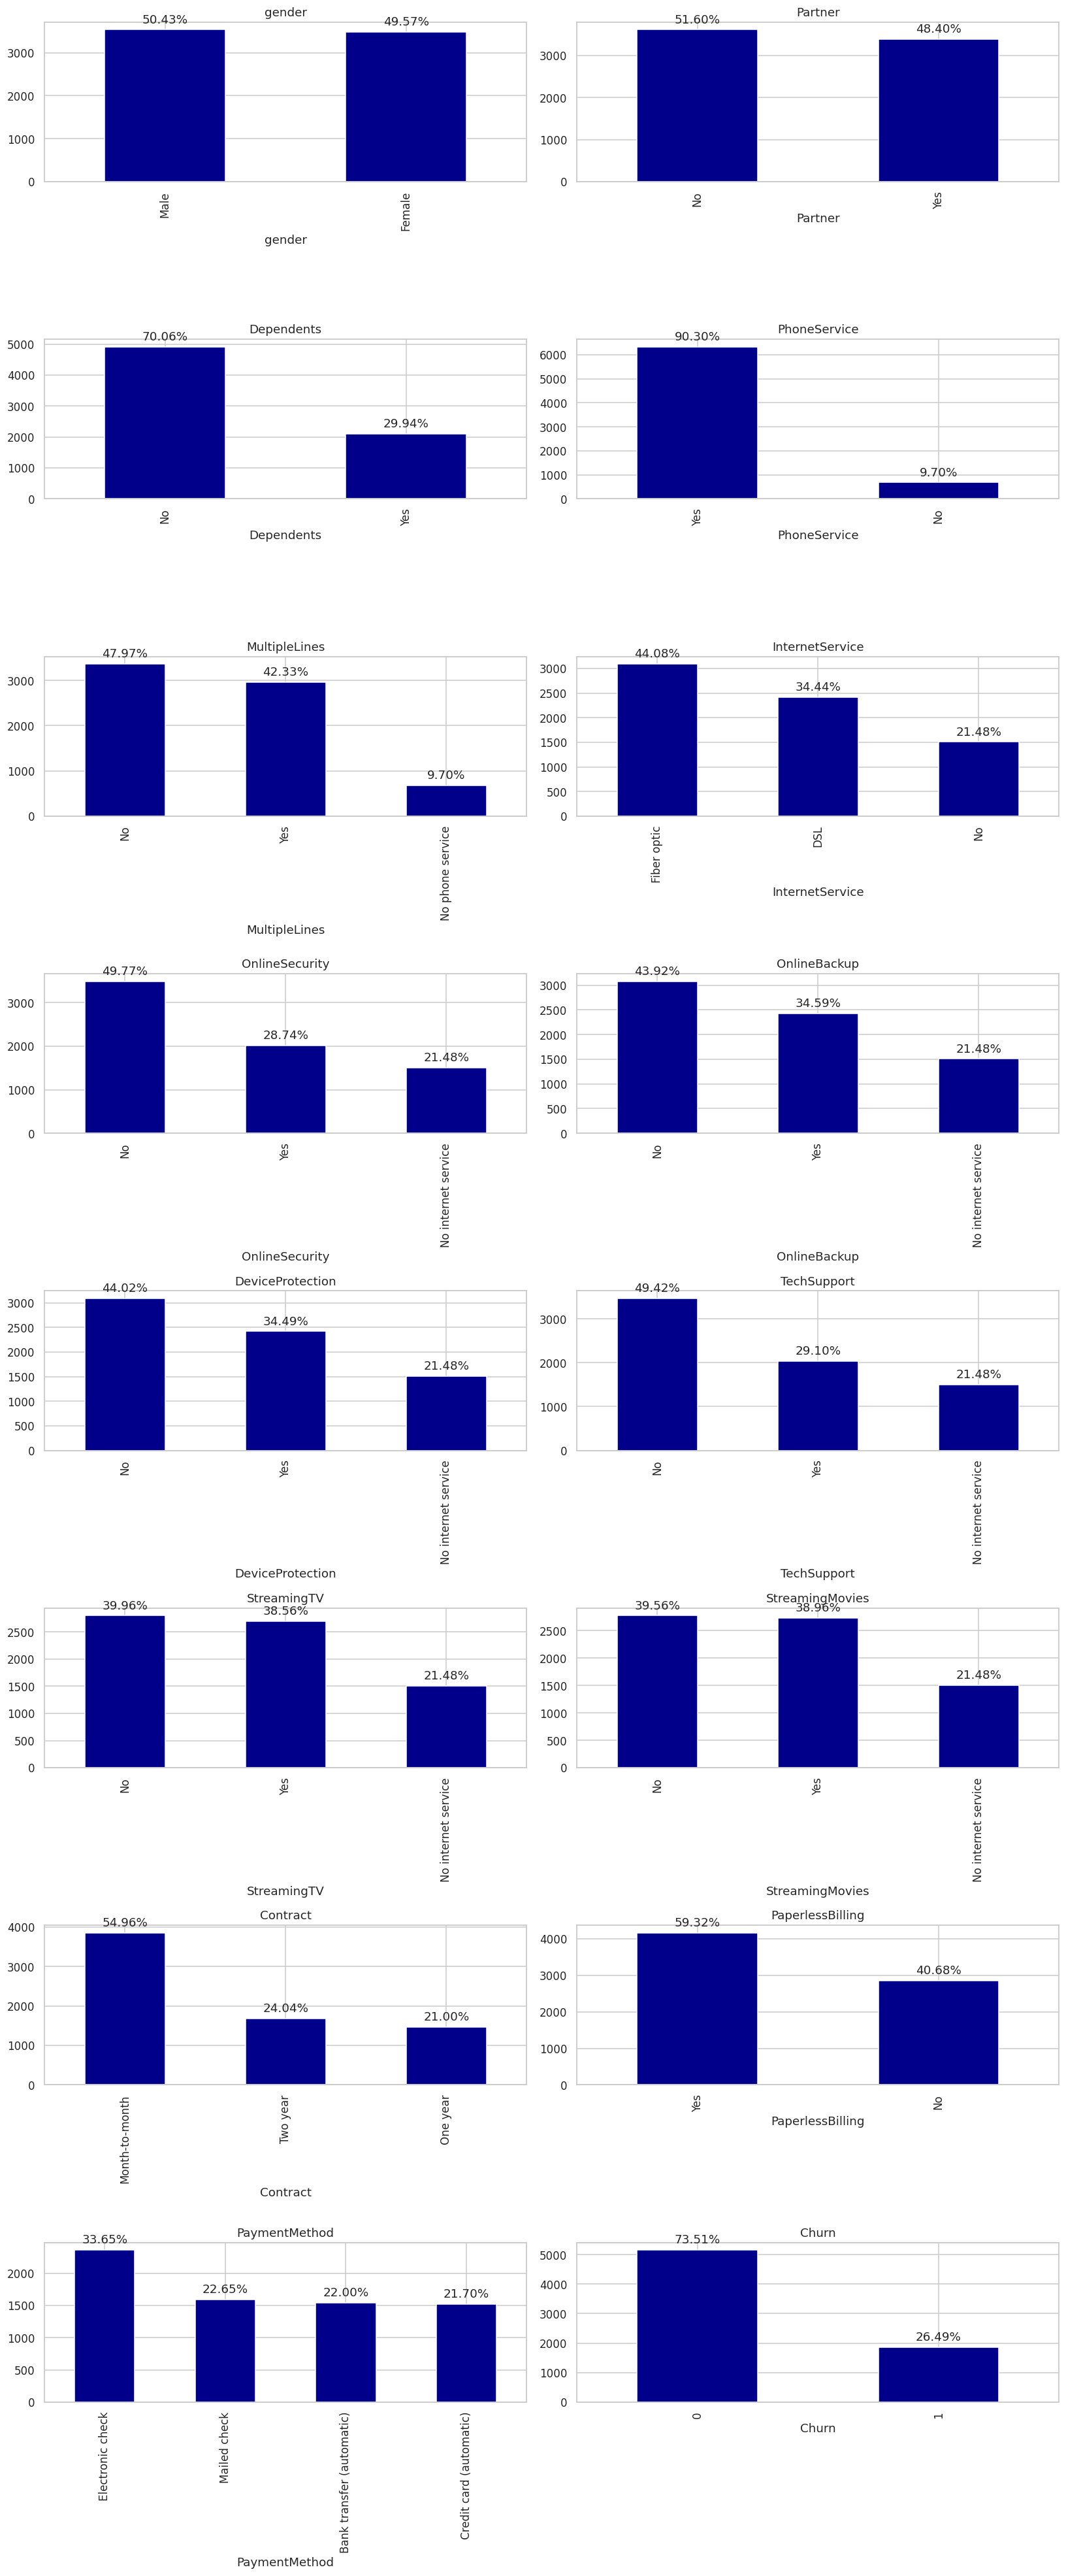

In [24]:
# Cuadrícula de gráficos de barras con el porcentaje sobre cada barra
columns_per_row = 2
num_rows = math.ceil(len(columnsString) / columns_per_row)

fig, axes = plt.subplots(nrows=num_rows, ncols=columns_per_row, figsize=(15, 4.5 * num_rows))
axes = axes.flatten()
color = "darkblue"

for i, (ax, x) in enumerate(zip(axes, columnsString)):
    counts = df2.fillna("--NULL")[x].value_counts()
    counts.plot(kind="bar", ax=ax, title=x, color=color)
    for p in ax.patches:
        porcentaje = f"{100 * p.get_height() / len(df2):.2f}%"
        ax.annotate(porcentaje,
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="center", xytext=(0, 10), textcoords="offset points")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 4. Estadísticos descriptivos y distribuciones

In [25]:
df2.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7010.00,7010.00,7010.00,7010.00,7010.00
mean,0.16,32.52,64.89,2290.35,0.26
std,0.37,24.52,30.06,2266.82,0.44
min,0.00,1.00,18.25,18.80,0.00
25%,0.00,9.00,35.75,408.31,0.00
50%,0.00,29.00,70.40,1403.88,0.00
75%,0.00,56.00,89.90,3807.84,1.00
max,1.00,72.00,118.75,8684.80,1.00


In [26]:
df2.describe(include="all").round(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7010,7010.00,7010,7010,7010.00,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010.00,7010.00,7010.00
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,NaN
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,NaN
freq,3535,NaN,3617,4911,NaN,6330,3363,3090,3489,3079,3086,3464,2801,2773,3853,4158,2359,NaN,NaN,NaN
mean,NaN,0.16,NaN,NaN,32.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.89,2290.35,0.26
std,NaN,0.37,NaN,NaN,24.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.06,2266.82,0.44
min,NaN,0.00,NaN,NaN,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.25,18.80,0.00
25%,NaN,0.00,NaN,NaN,9.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.75,408.31,0.00
50%,NaN,0.00,NaN,NaN,29.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.40,1403.88,0.00
75%,NaN,0.00,NaN,NaN,56.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.90,3807.84,1.00


* 16% de los clientes son personas senior
* En promedio los clientes permanecen en la compañía 32 meses
* El 50% de los clientes ha estado con la compañía a lo mucho 29 meses
* El cargo promedio mensual es de 64; el cargo máximo es de 118
* En promedio los cargos totales de los clientes han sido 2 290
* 26% de ratio de churn
* No se ven indicios de valores atípicos extremos en `tenure` ni en `MonthlyCharges`

### 4.1 Histogramas

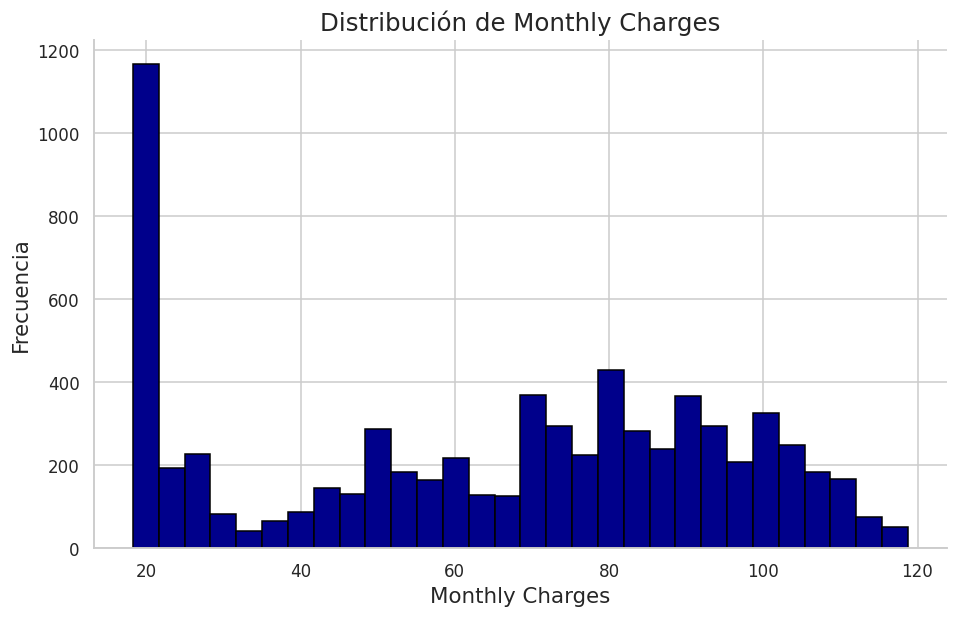

In [27]:
plt.figure(figsize=(10, 6))
plt.hist(df2["MonthlyCharges"], bins=30, color="darkblue", edgecolor="black")
plt.title("Distribución de Monthly Charges", fontsize=16)
plt.xlabel("Monthly Charges", fontsize=14)
plt.ylabel("Frecuencia", fontsize=14)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.show()

In [28]:
df2["MonthlyCharges"].mode()

,MonthlyCharges
0,20.05


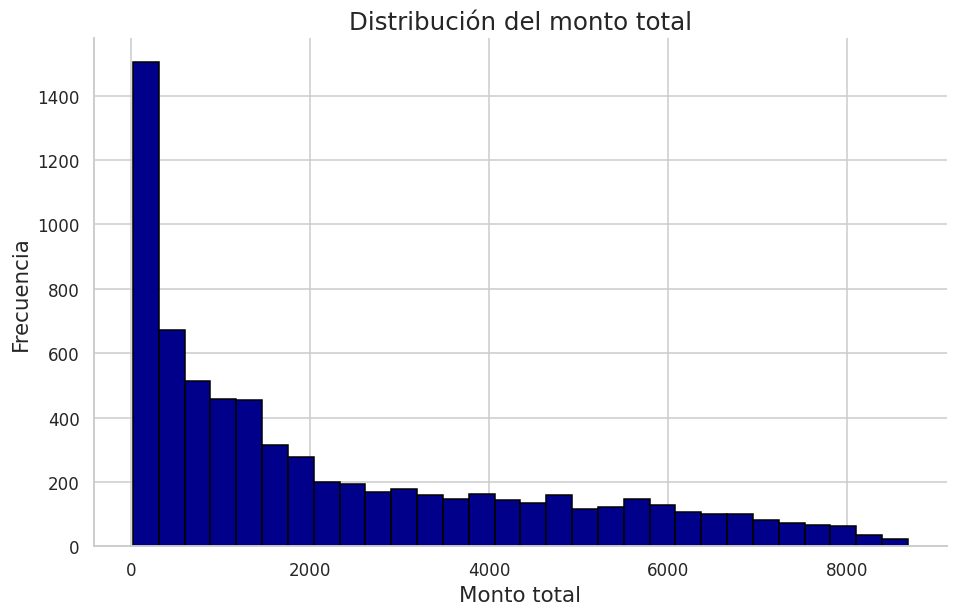

In [29]:
plt.figure(figsize=(10, 6))
plt.hist(df2["TotalCharges"], bins=30, color="darkblue", edgecolor="black")
plt.title("Distribución del monto total", fontsize=16)
plt.xlabel("Monto total", fontsize=14)
plt.ylabel("Frecuencia", fontsize=14)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.show()

In [30]:
df2["TotalCharges"].describe()

,TotalCharges
count,7010.000000
mean,2290.353388
std,2266.820832
min,18.800000
25%,408.312500
50%,1403.875000
75%,3807.837500
max,8684.800000


### 4.2 Boxplots — detección de valores atípicos

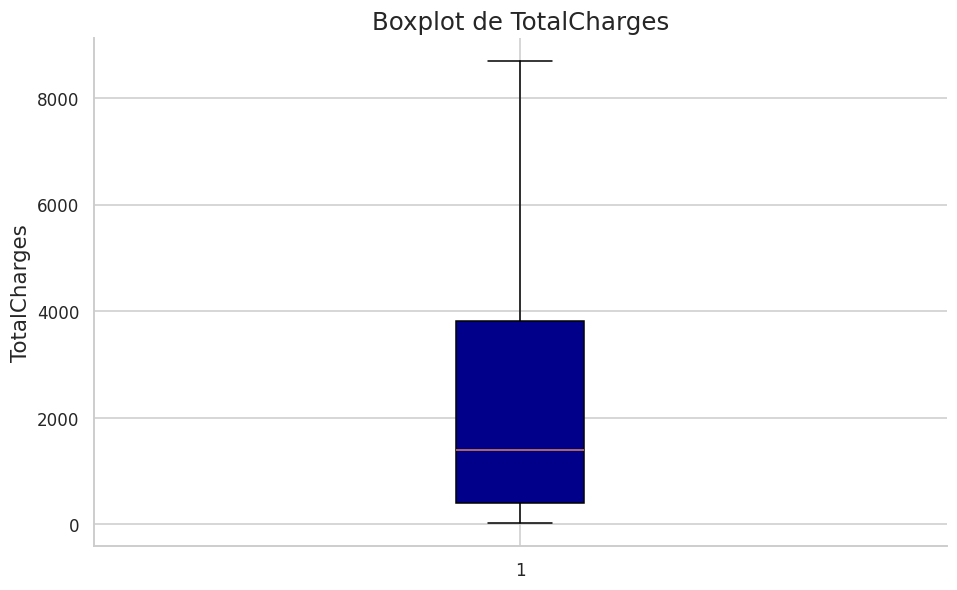

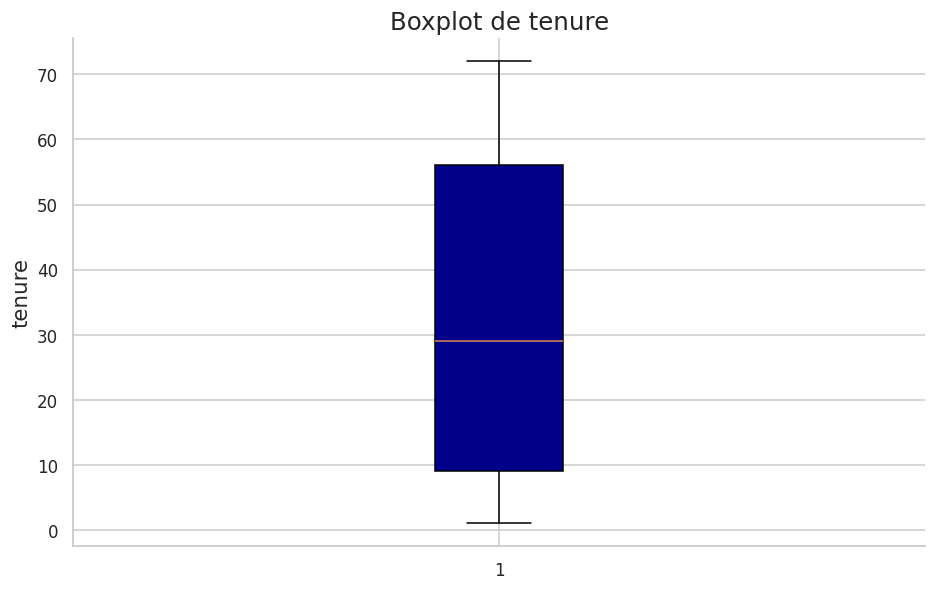

In [31]:
for col in ["TotalCharges", "tenure"]:
    plt.figure(figsize=(10, 6))
    plt.boxplot(df2[col], vert=True, patch_artist=True, boxprops=dict(facecolor="darkblue"))
    plt.title(f"Boxplot de {col}", fontsize=16)
    plt.ylabel(col, fontsize=14)
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.show()

## 5. Análisis bivariado

### 5.1 Variables numéricas según churn

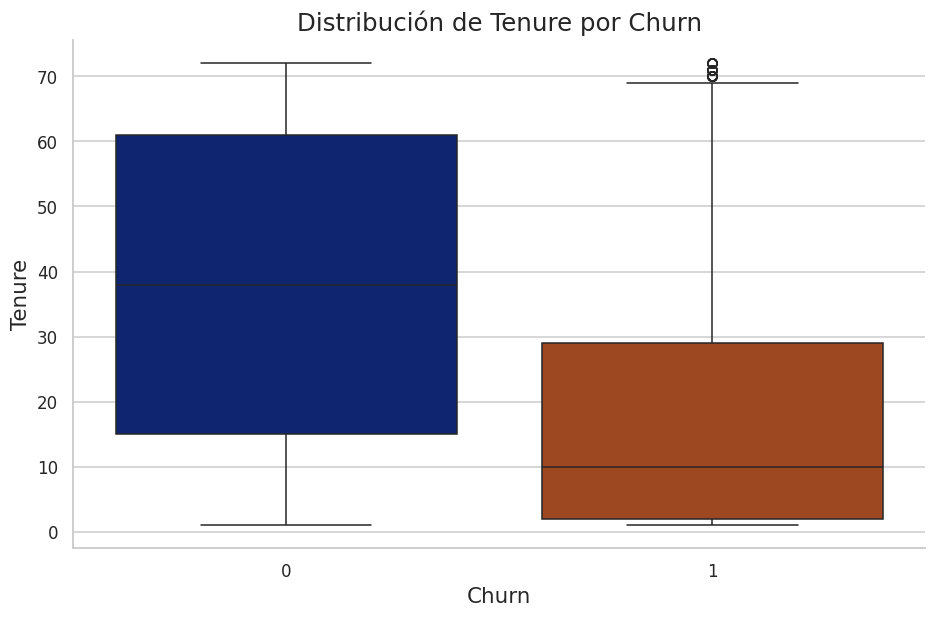

In [32]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df2.Churn, y=df2.tenure, hue=df2.Churn, palette="dark", linewidth=1, legend=False)
plt.title("Distribución de Tenure por Churn", fontsize=16)
plt.xlabel("Churn", fontsize=14)
plt.ylabel("Tenure", fontsize=14)
sns.despine(top=True, right=True)
plt.show()

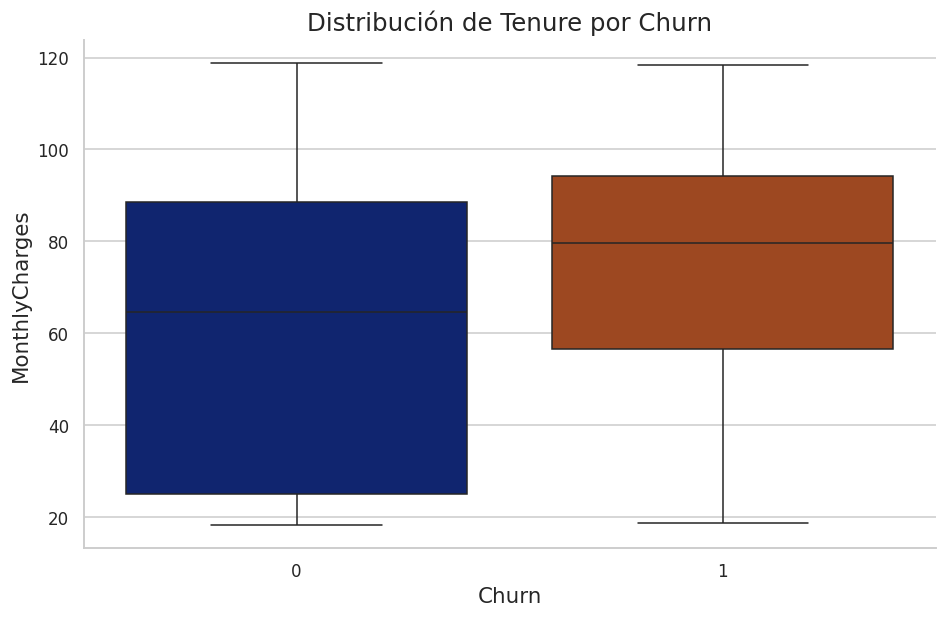

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df2.Churn, y=df2.MonthlyCharges, hue=df2.Churn, palette="dark", linewidth=1, legend=False)
plt.title("Distribución de Tenure por Churn", fontsize=16)
plt.xlabel("Churn", fontsize=14)
plt.ylabel("MonthlyCharges", fontsize=14)
sns.despine(top=True, right=True)
plt.show()

Los clientes que han fugado tienen menos meses en la compañía.

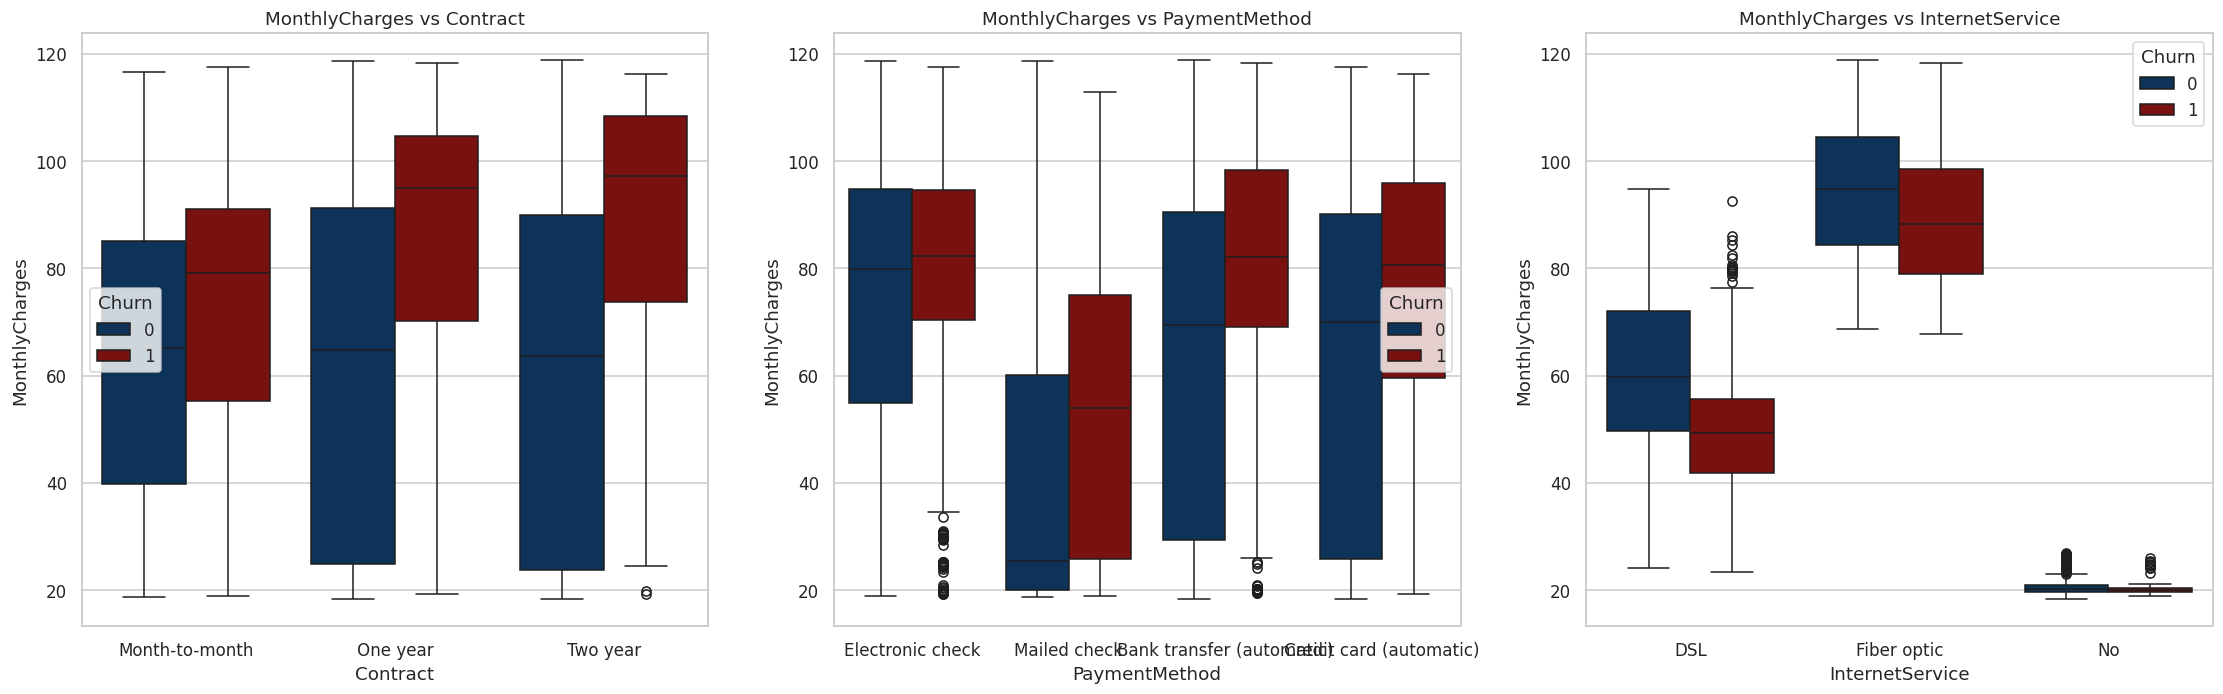

In [34]:
l3 = ["Contract", "PaymentMethod", "InternetService"]
colors = ["#003366", "#8B0000"]   # azul oscuro y rojo oscuro

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(25, 7))
for i in range(len(l3)):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x=l3[i], y="MonthlyCharges", data=df2, hue="Churn", palette=colors)
    plt.title("MonthlyCharges vs " + l3[i])
plt.show()

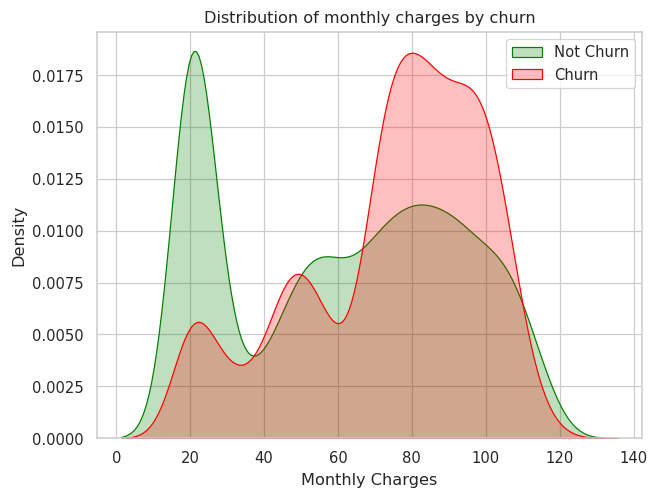

In [35]:
sns.set_context("paper", font_scale=1.1)
ax = sns.kdeplot(df2.MonthlyCharges[df2["Churn"] == 0], color="green", fill=True)
ax = sns.kdeplot(df2.MonthlyCharges[df2["Churn"] == 1], ax=ax, color="red", fill=True)
ax.legend(["Not Churn", "Churn"], loc="upper right")
ax.set_ylabel("Density")
ax.set_xlabel("Monthly Charges")
ax.set_title("Distribution of monthly charges by churn")
plt.show()

### 5.2 Churn por variable categórica

In [36]:
def churn_apilado(variable, data=df2):
    """Barras apiladas con el % de churn dentro de cada categoría."""
    tabla = data.groupby(variable)["Churn"].value_counts().unstack()
    tabla_perc = tabla.div(tabla.sum(1), axis=0) * 100

    ax = tabla_perc.plot(kind="bar", stacked=True, color=["#7f7f7f", "#8B0000"], figsize=(10, 6))
    plt.title(f"Churn by {variable}")
    plt.ylabel("% Customers")
    plt.xlabel(variable)
    plt.legend(title="Churn")
    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        x, y = p.get_xy()
        ax.annotate(f"{height:.0f}%", (x + width / 2, y + height / 2),
                    ha="center", va="center", color="white", fontsize=12, weight="bold")
    plt.show()
    return tabla_perc.round(1)

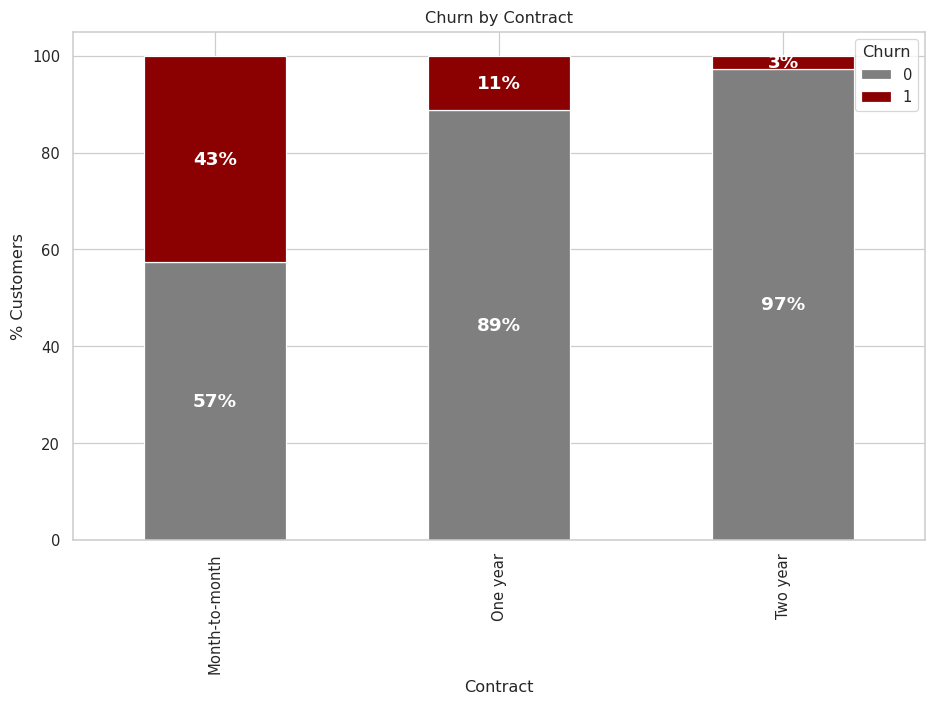

Churn,0,1
Contract,,
Month-to-month,57.4,42.6
One year,88.7,11.3
Two year,97.2,2.8


In [37]:
churn_apilado("Contract")

El 43% de los clientes con contrato mes a mes ha fugado, frente a solo el 3% de los que tienen contrato a 2 años.

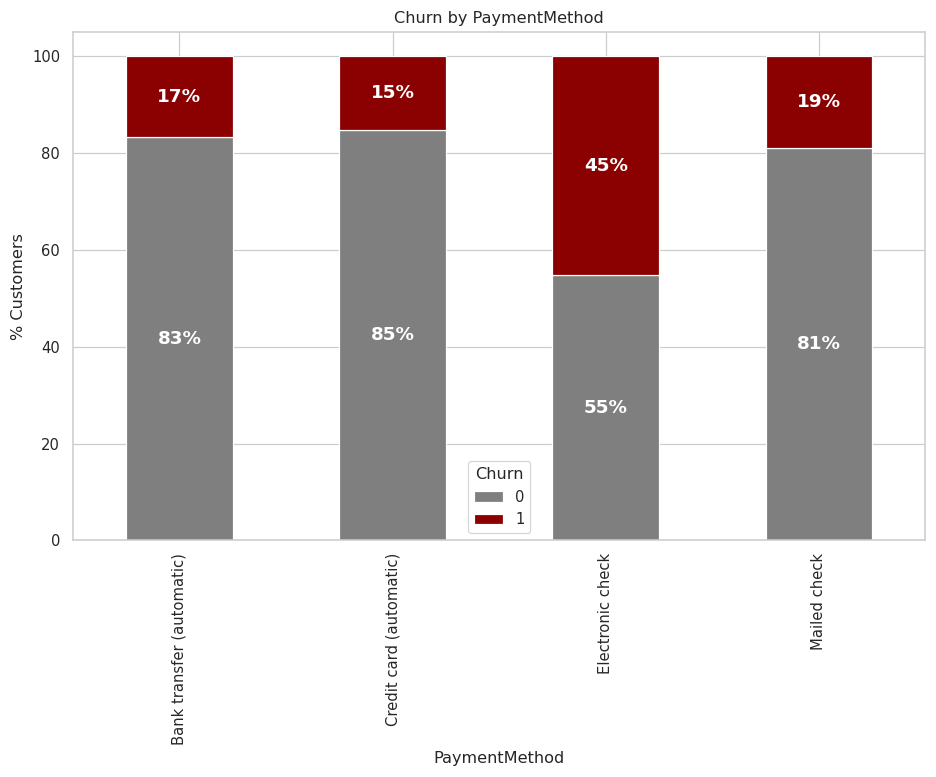

Churn,0,1
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.7,15.3
Electronic check,54.9,45.1
Mailed check,81.0,19.0


In [38]:
churn_apilado("PaymentMethod")

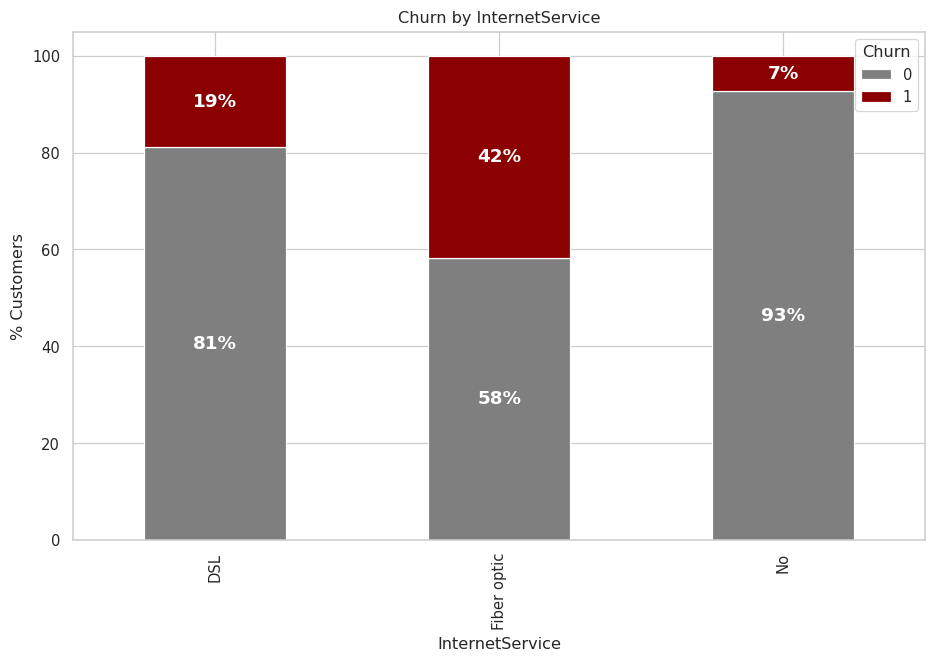

Churn,0,1
InternetService,,
DSL,81.1,18.9
Fiber optic,58.2,41.8
No,92.8,7.2


In [39]:
churn_apilado("InternetService")

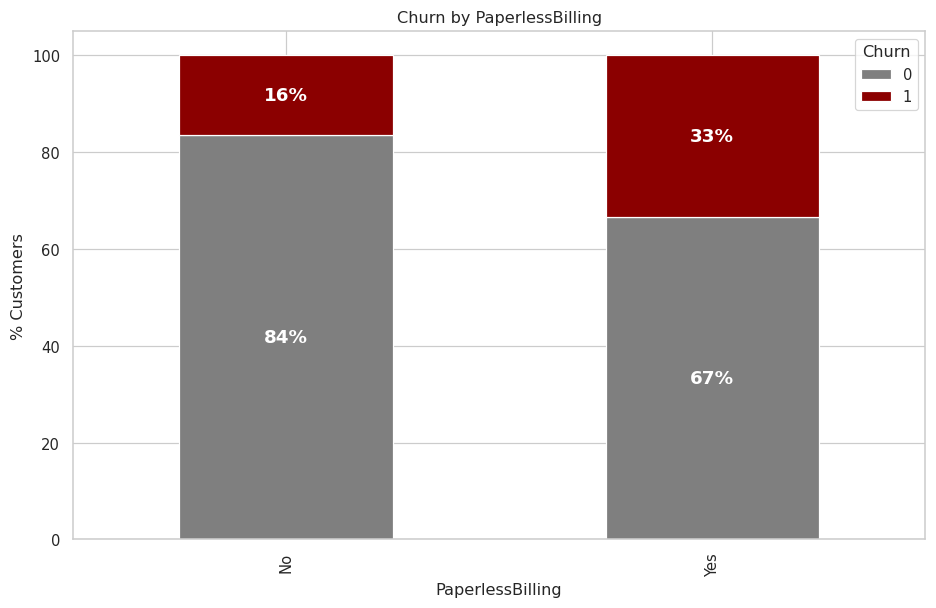

Churn,0,1
PaperlessBilling,,
No,83.7,16.3
Yes,66.5,33.5


In [40]:
churn_apilado("PaperlessBilling")

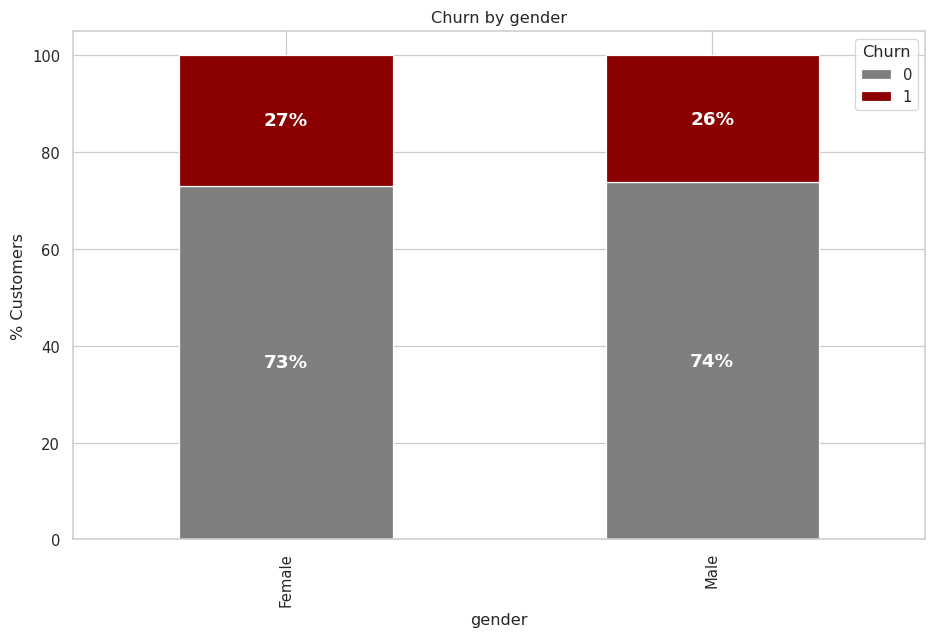

Churn,0,1
gender,,
Female,73.1,26.9
Male,73.9,26.1


In [41]:
churn_apilado("gender")

### 5.3 Tasa de fuga por categoría vs. tasa global

In [42]:
tasa_global = df2["Churn"].mean()
print(f"Tasa de fuga global: {tasa_global:.1%}")


def tasa_fuga(variable, data=df2):
    """Clientes, tasa de fuga e índice de cada categoría respecto de la tasa global."""
    t = data.groupby(variable)["Churn"].agg(Clientes="size", Fugados="sum", Tasa="mean")
    t["Tasa"] = (100 * t["Tasa"]).round(1)
    t["Indice"] = (t["Tasa"] / (100 * data["Churn"].mean())).round(2)
    return t.sort_values("Tasa", ascending=False)


tasa_fuga("Contract")

Tasa de fuga global: 26.5%


,Clientes,Fugados,Tasa,Indice
Contract,,,,
Month-to-month,3853,1643,42.6,1.61
One year,1472,166,11.3,0.43
Two year,1685,48,2.8,0.11


In [43]:
for x in columnsString[:-1]:      # todas las categóricas menos Churn
    print(tasa_fuga(x)[["Clientes", "Tasa", "Indice"]], "\n")

        Clientes  Tasa  Indice
gender                        
Female      3475  26.9    1.02
Male        3535  26.1    0.99 

         Clientes  Tasa  Indice
Partner                        
No           3617  32.8    1.24
Yes          3393  19.7    0.74 

            Clientes  Tasa  Indice
Dependents                        
No              4911  31.2    1.18
Yes             2099  15.5    0.59 

              Clientes  Tasa  Indice
PhoneService                        
Yes               6330  26.7    1.01
No                 680  25.0    0.94 

                  Clientes  Tasa  Indice
MultipleLines                           
Yes                   2967  28.6    1.08
No phone service       680  25.0    0.94
No                    3363  24.9    0.94 

                 Clientes  Tasa  Indice
InternetService                        
Fiber optic          3090  41.8    1.58
DSL                  2414  18.9    0.71
No                   1506   7.2    0.27 

                     Clientes  Tasa  Indice

### 5.4 Relaciones entre las variables numéricas

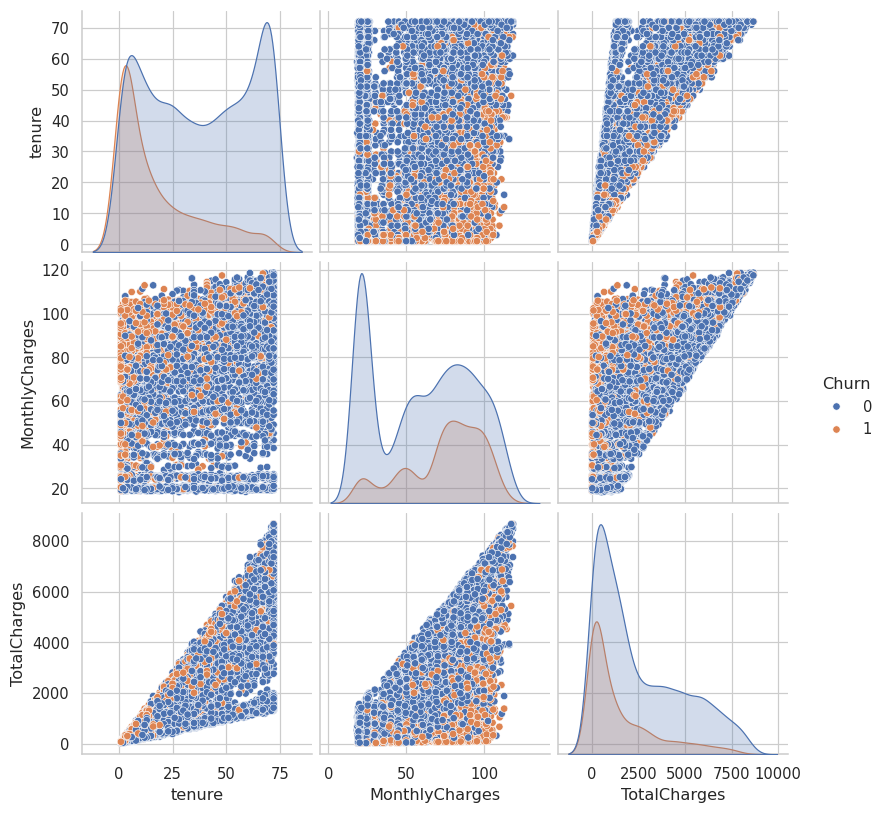

In [44]:
sns.pairplot(df2[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]], hue="Churn")
plt.show()

## 6. Correlaciones

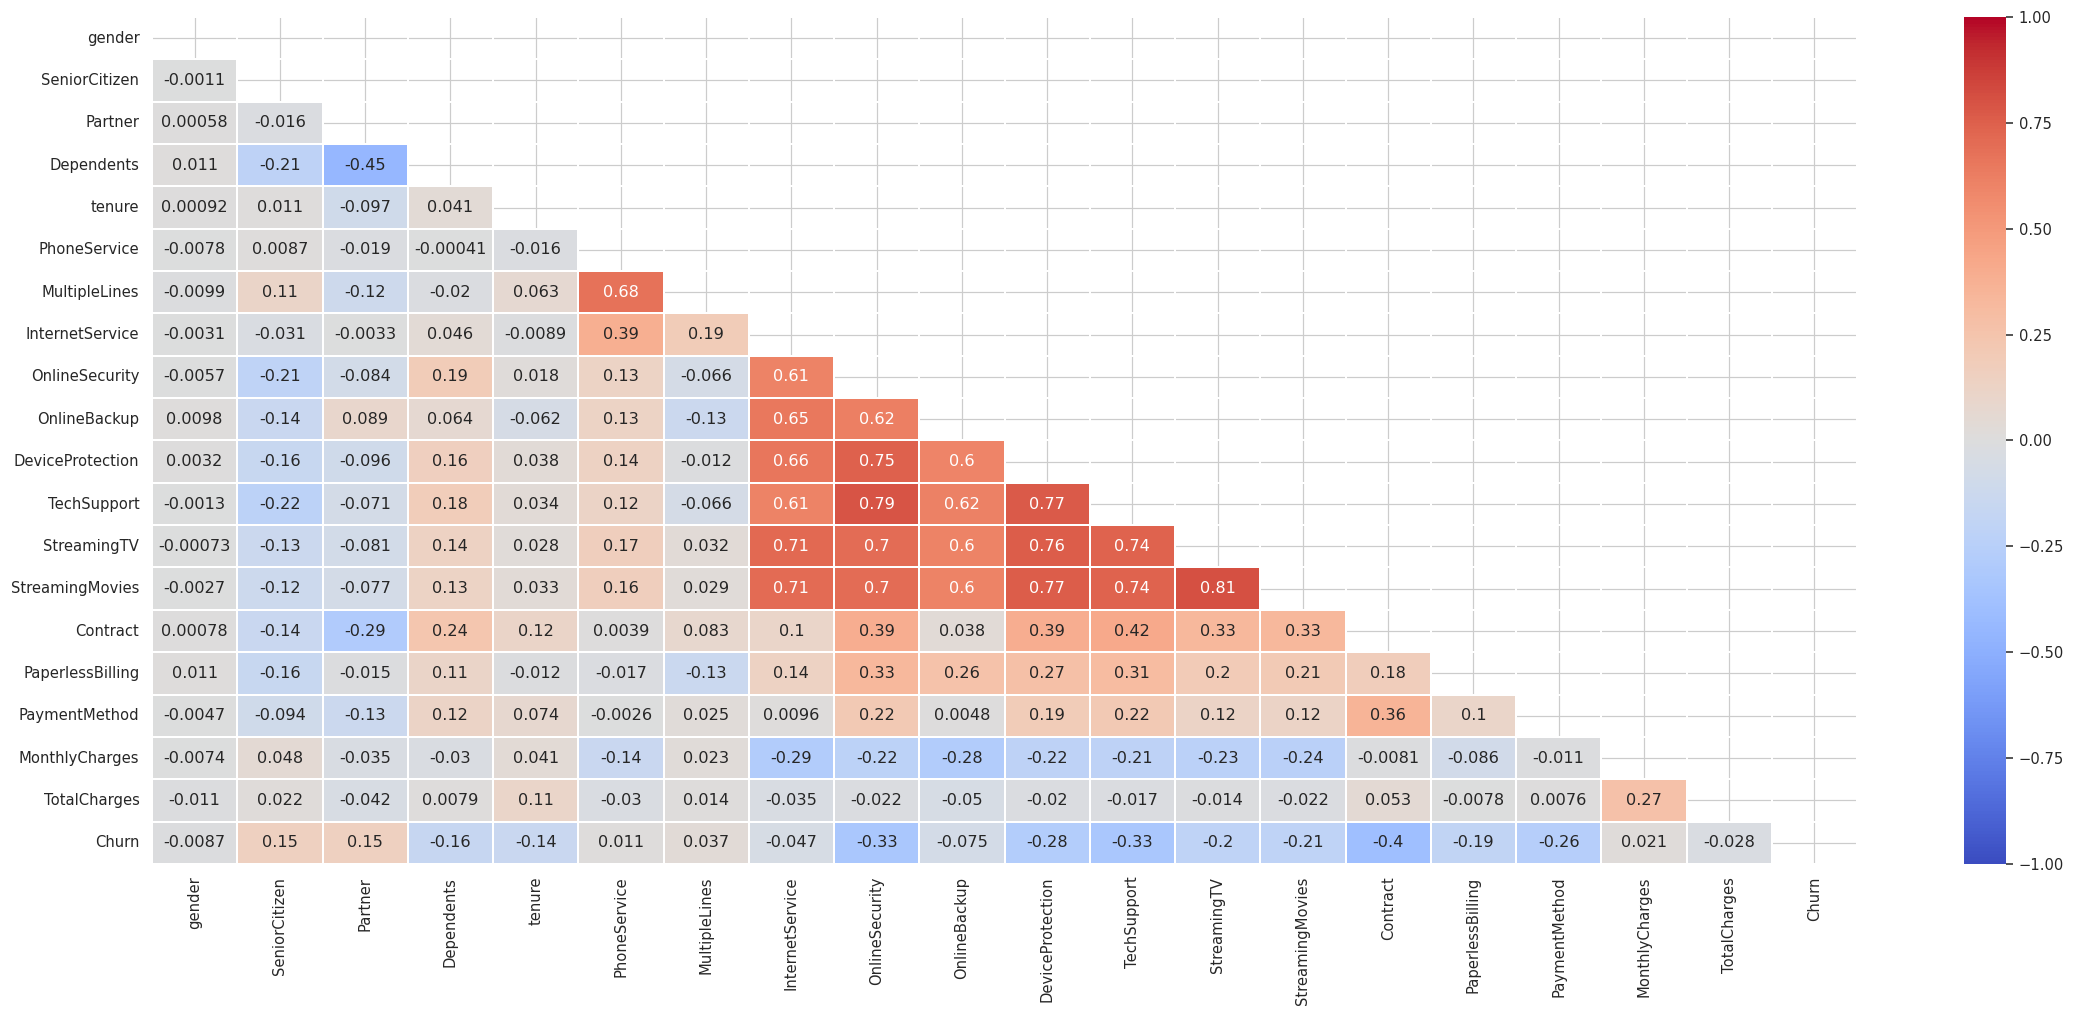

In [45]:
plt.figure(figsize=(25, 10))

# pd.factorize convierte las categóricas en códigos numéricos antes de correlacionar
corr = df2.apply(lambda x: pd.factorize(x)[0]).corr()

# Máscara triangular superior
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, xticklabels=corr.columns, yticklabels=corr.columns,
            annot=True, linewidths=.2, cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [47]:
df2.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


> `factorize` asigna códigos según el orden de aparición de cada categoría, por lo que la correlación entre variables nominales no es interpretable. La alternativa es binarizar (one-hot) y correlacionar contra la variable objetivo.

In [46]:
# Variables categóricas convertidas en dummies
df_dummies = pd.get_dummies(df2, dtype=int)
df_dummies.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,1,0,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0
1,0,34,56.95,1889.50,0,0,1,1,0,1,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,1,1,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,1
3,0,45,42.30,1840.75,0,0,1,1,0,1,0,1,0,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0,1,0,1,0,0,0
4,0,2,70.70,151.65,1,1,0,1,0,1,0,0,1,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0


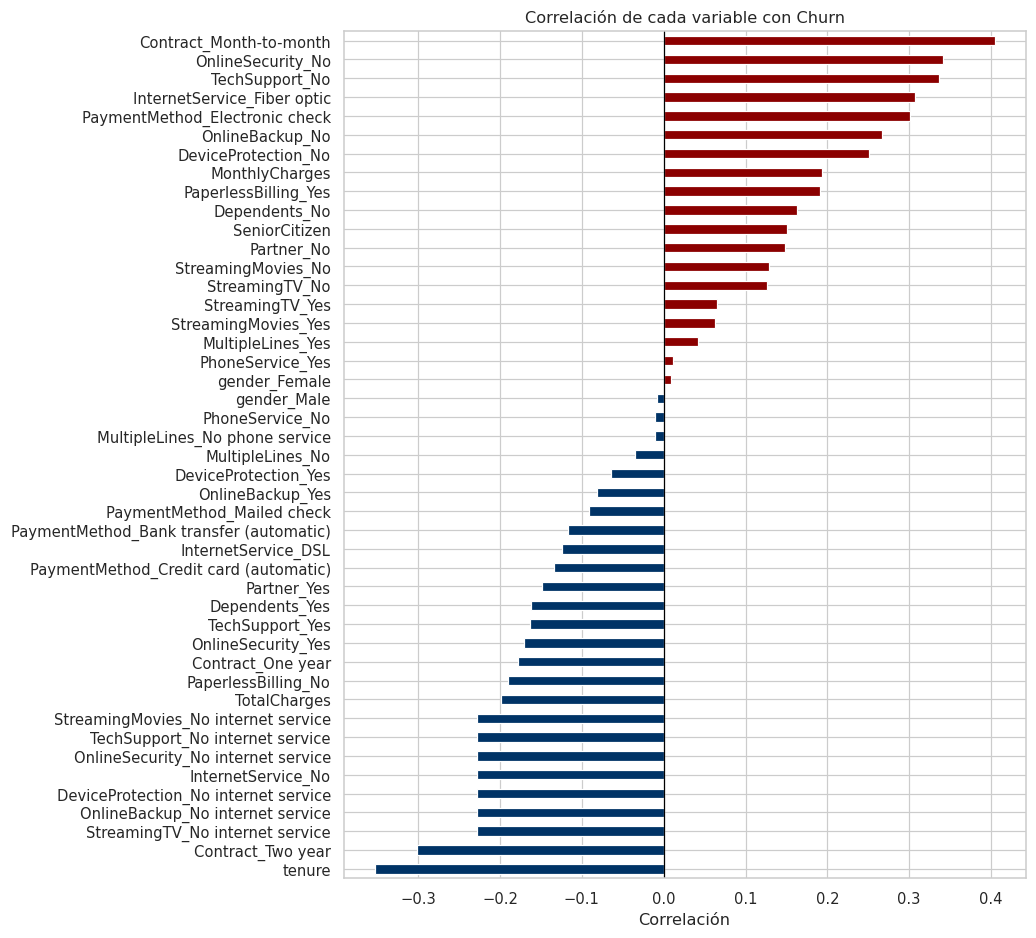

In [48]:
corr_churn = df_dummies.corr()["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(8, 10))
corr_churn.plot(kind="barh", color=["#003366" if v < 0 else "#8B0000" for v in corr_churn])
plt.axvline(0, color="black", lw=.8)
plt.title("Correlación de cada variable con Churn")
plt.xlabel("Correlación")
plt.show()

## 7. Perfiles agrupados

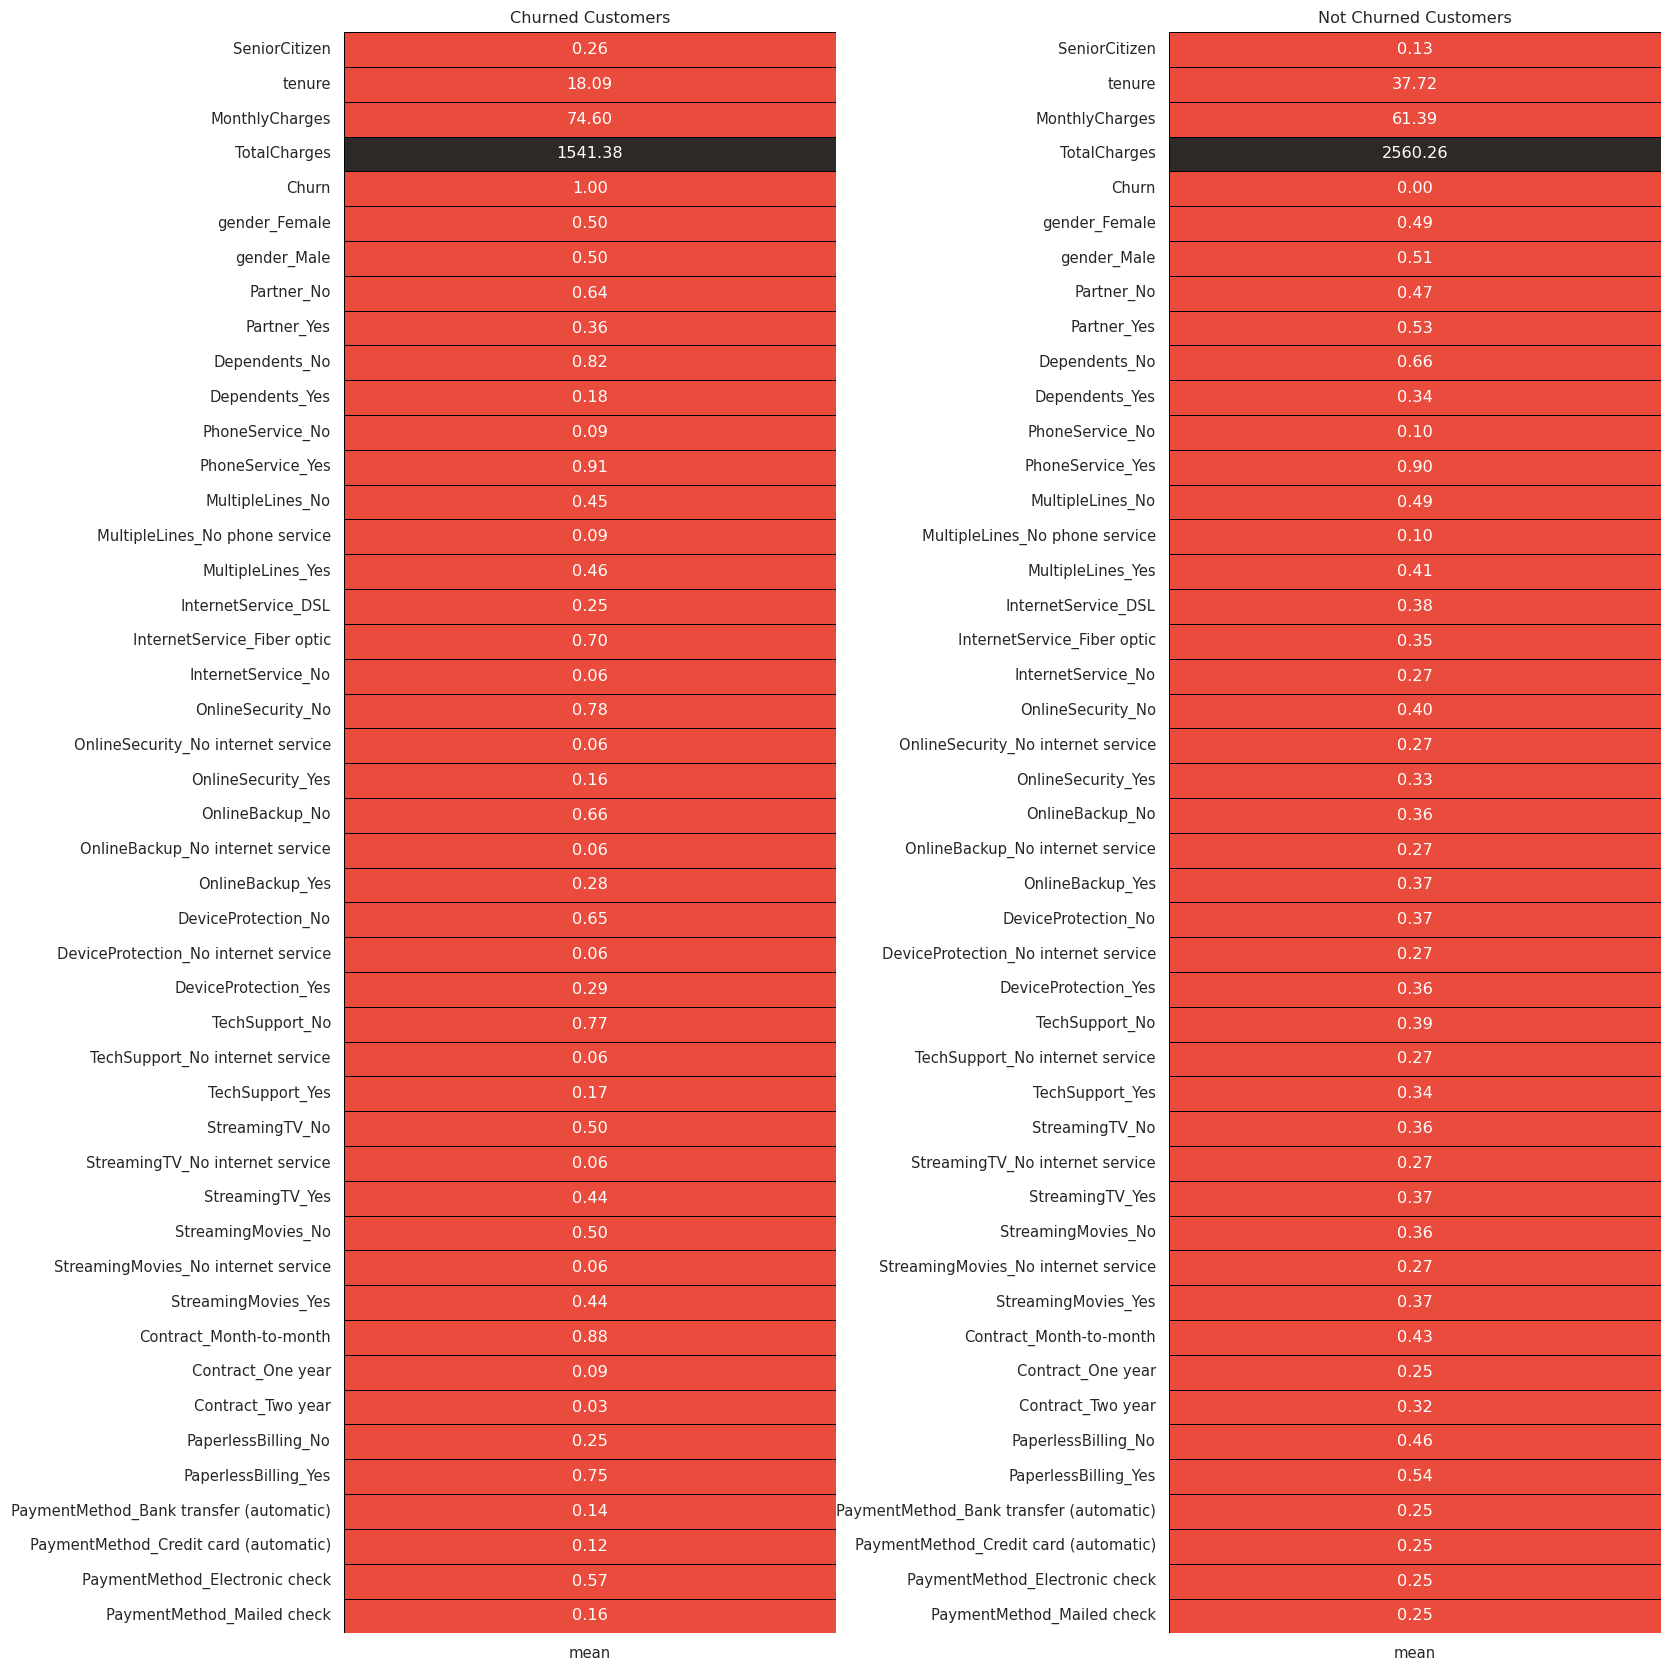

In [49]:
colors = ["#E94B3C", "#2D2926"]

churn = df_dummies[df_dummies["Churn"] == 1].describe().T
not_churn = df_dummies[df_dummies["Churn"] == 0].describe().T

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 15))

plt.subplot(1, 2, 1)
sns.heatmap(churn[["mean"]], annot=True, cmap=colors, linewidths=0.4,
            linecolor="black", cbar=False, fmt=".2f")
plt.title("Churned Customers")

plt.subplot(1, 2, 2)
sns.heatmap(not_churn[["mean"]], annot=True, cmap=colors, linewidths=0.4,
            linecolor="black", cbar=False, fmt=".2f")
plt.title("Not Churned Customers")

fig.tight_layout(pad=0)
plt.show()

In [50]:
# Comparación de medias entre ambos grupos
churn_summary = df_dummies.groupby("Churn").mean().transpose()
churn_summary.round(2)

Churn,0,1
SeniorCitizen,0.13,0.26
tenure,37.72,18.09
MonthlyCharges,61.39,74.60
TotalCharges,2560.26,1541.38
gender_Female,0.49,0.50
gender_Male,0.51,0.50
Partner_No,0.47,0.64
Partner_Yes,0.53,0.36
Dependents_No,0.66,0.82
Dependents_Yes,0.34,0.18


In [51]:
grouped_stats = df2.groupby(["PaymentMethod", "Churn"]).agg(
    AvgMonthlyCharges=("MonthlyCharges", "mean"),
    Avg_tenure=("tenure", "mean"),
    MedianTotalCharges=("TotalCharges", "median"),
    AvgTotalCharges=("TotalCharges", "mean")
).reset_index()
grouped_stats.round(2)

,PaymentMethod,Churn,AvgMonthlyCharges,Avg_tenure,MedianTotalCharges,AvgTotalCharges
0,Bank transfer (automatic),0,65.06,47.21,2673.80,3241.95
1,Bank transfer (automatic),1,77.88,26.29,1306.70,2269.81
2,Credit card (automatic),0,64.57,46.14,2633.30,3201.19
3,Credit card (automatic),1,77.36,27.52,1478.40,2350.26
4,Electronic check,0,74.23,32.14,1883.85,2609.99
5,Electronic check,1,78.77,16.85,713.10,1471.53
6,Mailed check,0,41.61,25.43,602.25,1187.18
7,Mailed check,1,54.99,8.20,120.38,543.98


In [52]:
grouped_stats = df2.groupby(["Churn"]).agg(
    AvgMonthlyCharges=("MonthlyCharges", "mean"),
    Avg_tenure=("tenure", "mean"),
    MedianTotalCharges=("TotalCharges", "median"),
    SumaMonthlyCharges=("MonthlyCharges", "sum"),
    AvgTotalCharges=("TotalCharges", "mean")
).reset_index()
grouped_stats.round(2)

,Churn,AvgMonthlyCharges,Avg_tenure,MedianTotalCharges,SumaMonthlyCharges,AvgTotalCharges
0,0,61.39,37.72,1688.9,316329.35,2560.26
1,1,74.60,18.09,713.1,138540.20,1541.38


In [53]:
df2.groupby(["PaymentMethod", "Churn"]).describe()

SeniorCitizen                                \
                                        count      mean       std  min  25%   
PaymentMethod             Churn                                               
Bank transfer (automatic) 0            1284.0  0.140187  0.347316  0.0  0.0   
                          1             258.0  0.205426  0.404798  0.0  0.0   
Credit card (automatic)   0            1289.0  0.123351  0.328968  0.0  0.0   
                          1             232.0  0.267241  0.443476  0.0  0.0   
Electronic check          0            1294.0  0.214065  0.410331  0.0  0.0   
                          1            1065.0  0.296714  0.457024  0.0  0.0   
Mailed check              0            1286.0  0.038880  0.193385  0.0  0.0   
                          1             302.0  0.145695  0.353386  0.0  0.0   

                                                tenure                        \
                                 50%  75%  max   count       mean        std   
PaymentMethod             Churn                                                
Bank transfer (automatic) 0      0.0  0.0  1.0  1284.0  47.214174  21.799878   
                          1      0.0  0.0  1.0   258.0  26.290698  21.855486   
Credit card (automatic)   0      0.0  0.0  1.0  1289.0  46.137316  22.388695   
                          1      0.0  1.0  1.0   232.0  27.521552  22.109516   
Electronic check          0      0.0  0.0  1.0  1294.0  32.136012  22.968893   
                          1      0.0  1.0  1.0  1065.0  16.852582  18.449429   
Mailed check              0      0.0  0.0  1.0  1286.0  25.426905  21.603153   
                          1      0.0  0.0  1.0   302.0   8.195364  11.821411   

                                                              MonthlyCharges  \
                                 min    25%   50%   75%   max          count   
PaymentMethod             Churn                                                
Bank transfer (automatic) 0      1.0  29.75  52.0  68.0  72.0         1284.0   
                          1      1.0   7.00  21.0  46.0  72.0          258.0   
Credit card (automatic)   0      1.0  27.00  51.0  67.0  72.0         1289.0   
                          1      1.0   7.75  22.5  45.0  72.0          232.0   
Electronic check          0      1.0  11.00  30.0  53.0  72.0         1294.0   
                          1      1.0   2.00   9.0  26.0  72.0         1065.0   
Mailed check              0      1.0   6.00  20.0  41.0  72.0         1286.0   
                          1      1.0   1.00   3.0  10.0  61.0          302.0   

                                                                               \
                                      mean        std    min      25%     50%   
PaymentMethod             Churn                                                 
Bank transfer (automatic) 0      65.061604  31.017119  18.40  29.3500  69.500   
                          1      77.875581  25.774626  19.40  69.1250  82.075   
Credit card (automatic)   0      64.568813  31.322307  18.25  25.8000  69.950   
                          1      77.356034  23.673652  19.30  59.4625  80.575   
Electronic check          0      74.232032  26.094541  18.85  54.8625  79.800   
                          1      78.774930  21.108528  19.25  70.3000  82.300   
Mailed check              0      41.605599  25.695783  18.70  20.0500  25.450   
                          1      54.988079  26.376810  18.85  25.7250  53.875   

                                                 TotalCharges               \
                                     75%     max        count         mean   
PaymentMethod             Churn                                              
Bank transfer (automatic) 0      90.4750  118.75       1284.0  3241.953388   
                          1      98.2625  118.35        258.0  2269.812984   
Credit card (automatic)   0      90.2000  117.50       1289.0  3201.189721   
                          1      95.9625

## 8. Insights

### 8.1 Ingreso mensual en riesgo

In [54]:
ingreso_total = df2["MonthlyCharges"].sum()
ingreso_riesgo = df2.loc[df2["Churn"] == 1, "MonthlyCharges"].sum()

print(f"Ingreso mensual facturado:  US$ {ingreso_total:,.0f}")
print(f"Ingreso mensual en riesgo:  US$ {ingreso_riesgo:,.0f}  ({ingreso_riesgo / ingreso_total:.1%})")
print(f"Proyección anualizada:      US$ {ingreso_riesgo * 12:,.0f}")

Ingreso mensual facturado:  US$ 454,870
Ingreso mensual en riesgo:  US$ 138,540  (30.5%)
Proyección anualizada:      US$ 1,662,482


### 8.2 Hallazgos y recomendación

Máximo 5 hallazgos, cada uno respaldado por una tabla o gráfico del cuaderno.

1. Del total de clienntte el 26% a fugado , lo que reprresenta representa una pérdida mensual de 138k y anual de 1.6MM.
2. Revisar el pricing vs competencia para dar servicios de valor agregado a los principales clientes, dado que los clientes que han fugado tienen cargo o mensual mayor vs a los que no.
3. Clientes con metodo de pago tarjeta de credito automatico (15%) tienen fuga menor, por lo tantoo sugerimos realizar un acampaña que promueva la afiliación a descuento autoomatico.
4. Los clientes con contrato mensual tienen una fuga de 48% vs los que tienen contrato anual y cada 2 años que tienen 11% y 3% respectivamente.
5. Los clientes nuevos son los que tienen mayor fuga , se recomienda realizar  un plan de onboarding.

**Recomendación para el área comercial:**

## 9. Preparación para el modelado

Todo lo anterior fue análisis exploratorio: entender los datos y describir patrones. Para que un
algoritmo de clasificación pueda usarlos, falta un paso que el EDA no resuelve por sí solo: casi
todas las columnas de `df2` son **texto** (`Contract`, `PaymentMethod`, `InternetService`, etc.), y
`scikit-learn` solo entrena con números.

### 9.1 Librerías adicionales

Las librerías de la sección 0 sirvieron para el EDA. Para modelar se necesitan además las
utilidades de partición, escalado, los tres algoritmos de clasificación y las métricas de
evaluación.

In [55]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

SEMILLA   = 42     # random_state único para todo el cuaderno
TEST_SIZE = 0.30   # 30% de los datos se reservan para evaluación
TARGET    = "Churn"

### 9.2 El one-hot encoding: de `df2` a un dataframe 100% numérico

En la sección 6 ya usamos `pd.get_dummies` — pero solo para poder calcular una correlación y
graficarla. Ahora le damos el uso real: convertir cada categoría de cada variable de texto en una
columna binaria (0/1), de modo que el dataframe completo quede listo para entrenar un modelo.

Con `drop_first=True` se elimina una categoría de referencia por variable (por ejemplo, si
`gender` tiene "Female" y "Male", solo queda la columna `gender_Male`: 0 = Female, 1 = Male).
Esto evita la **trampa de las dummies** (columnas perfectamente redundantes entre sí), algo que
no nos importaba para el heatmap de la sección 6 pero que sí afecta a un modelo como la
regresión logística.

In [56]:
df_modelo = pd.get_dummies(df2, drop_first=True, dtype=int)

print(f"df2      → {df2.shape[1]} columnas (con texto)")
print(f"df_modelo → {df_modelo.shape[1]} columnas (100% numéricas)")
df_modelo.head()

df2      → 20 columnas (con texto)
df_modelo → 31 columnas (100% numéricas)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [57]:
# Todas las columnas quedaron numéricas: ya se puede alimentar a scikit-learn
df_modelo.dtypes.value_counts()

,count
int64,29
float64,2


### 9.3 Separar predictores del objetivo

In [63]:
X = df_modelo.drop(columns=[TARGET])
y = df_modelo[TARGET]

print(f"X → {X.shape[0]:,} filas × {X.shape[1]} variables")
print(f"y → {y.shape[0]:,} etiquetas")

X → 7,010 filas × 30 variables
y → 7,010 etiquetas


### 9.4 Partición train / test

Igual que en la Sesión 5: `stratify=y` conserva la proporción de fuga en ambos conjuntos, y
`random_state=SEMILLA` hace la partición reproducible. El modelo nunca ve el conjunto de test
durante el entrenamiento.

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=SEMILLA,
    stratify=y
)

resumen_particion = pd.DataFrame({
    "Clientes":       [len(X_train), len(X_test)],
    "% del total":    [len(X_train) / len(X) * 100, len(X_test) / len(X) * 100],
    "Tasa de fuga":   [y_train.mean(), y_test.mean()],
}, index=["Train", "Test"]).round(3)

print(resumen_particion.to_string())
print("\n→ La tasa de fuga es prácticamente idéntica en ambos conjuntos: la estratificación funcionó.")

       Clientes  % del total  Tasa de fuga
Train      4907         70.0         0.265
Test       2103         30.0         0.265

→ La tasa de fuga es prácticamente idéntica en ambos conjuntos: la estratificación funcionó.


### 9.5 Caja de herramientas de evaluación

Las mismas funciones que en la Sesión 5, para mantener el mismo estándar: **ningún indicador se
reporta solo en test**, siempre se compara train vs. test.

In [60]:
def calcular_metricas(y_real, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    auc = roc_auc_score(y_real, y_proba)
    return {
        "Accuracy":      accuracy_score(y_real, y_pred),
        "Precision":     precision_score(y_real, y_pred, zero_division=0),
        "Recall":        recall_score(y_real, y_pred),
        "Especificidad": tn / (tn + fp),
        "F1":            f1_score(y_real, y_pred),
        "AUC":           auc,
        "Gini":          2 * auc - 1,
    }


def evaluar_modelo(modelo, X_tr, y_tr, X_te, y_te, nombre, umbral=0.5, entrenar=True):
    if entrenar:
        modelo.fit(X_tr, y_tr)

    filas = {}
    for etiqueta, (X_, y_) in {"Train": (X_tr, y_tr), "Test": (X_te, y_te)}.items():
        proba = modelo.predict_proba(X_)[:, 1]
        pred  = (proba >= umbral).astype(int)
        filas[etiqueta] = calcular_metricas(y_, pred, proba)

    res = pd.DataFrame(filas).T
    res.index.name = "Partición"
    res.insert(0, "Modelo", nombre)
    return res


def diagnostico_sobreajuste(resultado, metrica="Accuracy", tolerancia=0.05):
    tr, te = resultado.loc["Train", metrica], resultado.loc["Test", metrica]
    brecha = tr - te
    if brecha > tolerancia:
        veredicto = "⚠️  SOBREAJUSTE — el modelo memorizó el train"
    elif brecha < -tolerancia:
        veredicto = "🔎 Test mejor que train — revisar la partición"
    else:
        veredicto = "✅ Generaliza bien — la brecha es aceptable"
    print(f"{metrica:<14} Train = {tr:.3f}   Test = {te:.3f}   "
          f"Brecha = {brecha:+.3f}\n{veredicto}")
    return brecha


def graficar_matrices_confusion(modelo, X_tr, y_tr, X_te, y_te, nombre, umbral=0.5):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for ax, etiqueta, (X_, y_) in zip(axes, ["Train", "Test"], [(X_tr, y_tr), (X_te, y_te)]):
        pred = (modelo.predict_proba(X_)[:, 1] >= umbral).astype(int)
        cm   = confusion_matrix(y_, pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    linewidths=1.2, linecolor="white", annot_kws={"size": 14},
                    xticklabels=["Pred. 0", "Pred. 1"], yticklabels=["Real 0", "Real 1"])
        acc = accuracy_score(y_, pred)
        ax.set_title(f"{etiqueta} — Accuracy {acc:.3f}", fontweight="bold")
    fig.suptitle(f"Matriz de confusión — {nombre}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def graficar_roc(modelo, X_tr, y_tr, X_te, y_te, nombre):
    plt.figure(figsize=(6.5, 5.5))
    plt.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.500)")
    for etiqueta, (X_, y_), color in zip(["Train", "Test"], [(X_tr, y_tr), (X_te, y_te)],
                                          ["#9AA5B1", "#003366"]):
        proba = modelo.predict_proba(X_)[:, 1]
        fpr, tpr, _ = roc_curve(y_, proba)
        auc = roc_auc_score(y_, proba)
        plt.plot(fpr, tpr, color=color, lw=2.2, label=f"{etiqueta} — AUC = {auc:.3f}")
    plt.xlabel("Tasa de falsos positivos  (1 − especificidad)")
    plt.ylabel("Tasa de verdaderos positivos  (recall)")
    plt.title(f"Curva ROC — {nombre}", fontweight="bold")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


def graficar_importancias(valores, columnas, titulo, xlabel="Importancia"):
    imp = (pd.DataFrame({"Variable": columnas, "Valor": valores})
             .assign(abs_val=lambda d: d["Valor"].abs())
             .sort_values("abs_val", ascending=False)
             .head(15))
    plt.figure(figsize=(8, 0.45 * len(imp) + 1.5))
    colores = ["#003366" if v >= 0 else "#8B0000" for v in imp["Valor"]]
    plt.barh(imp["Variable"], imp["Valor"], color=colores, edgecolor="white")
    plt.gca().invert_yaxis()
    plt.xlabel(xlabel)
    plt.title(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()
    return imp.drop(columns="abs_val").reset_index(drop=True)


def barrido_umbral(y_real, y_proba, umbrales=np.arange(0.1, 0.95, 0.05)):
    filas = []
    for u in umbrales:
        pred = (y_proba >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
        filas.append({
            "Umbral": round(u, 2), "Contactados": int(pred.sum()),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "Precision": precision_score(y_real, pred, zero_division=0),
            "Recall":    recall_score(y_real, pred),
            "F1":        f1_score(y_real, pred),
        })
    return pd.DataFrame(filas)


def tabla_deciles(y_real, y_proba, n=10):
    d = pd.DataFrame({"score": y_proba, "real": np.asarray(y_real)})
    d["Decil"] = pd.qcut(d["score"].rank(method="first"), n, labels=range(1, n + 1))
    d["Decil"] = (n + 1) - d["Decil"].astype(int)
    tabla = (d.groupby("Decil")
               .agg(Clientes=("real", "size"), Fugados=("real", "sum"), Tasa_fuga=("real", "mean"),
                    Score_min=("score", "min"), Score_max=("score", "max"))
               .sort_index())
    tasa_global_ = d["real"].mean()
    tabla["Lift"] = tabla["Tasa_fuga"] / tasa_global_
    tabla["Captura_acum_%"] = tabla["Fugados"].cumsum() / tabla["Fugados"].sum() * 100
    return tabla

## 10. Modelo 1 — Regresión logística

Empezamos por el modelo más simple: será la **línea base** que los modelos siguientes tendrán
que superar para justificar su mayor complejidad.

### 10.1 Entrenamiento

`tenure`, `MonthlyCharges` y `TotalCharges` están en escalas muy distintas entre sí y frente a las
columnas dummy (que solo valen 0 o 1). La regresión logística sí necesita escalar, así que se usa
un `Pipeline`: el escalador se ajusta **solo con train** y esa misma transformación se aplica a
test, para no filtrar información (*data leakage*).

In [65]:
modelo_log = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=SEMILLA))
])

modelo_log.fit(X_train, y_train)
print("Modelo entrenado.")
print(f'Intercepto (β₀): {modelo_log.named_steps["clasificador"].intercept_[0]:.4f}')

Modelo entrenado.
Intercepto (β₀): -1.7093


### 10.2 Los indicadores: train vs. test

In [66]:
res_log = evaluar_modelo(modelo_log, X_train, y_train, X_test, y_test,
                         nombre="Regresión logística", entrenar=False)
res_log.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Regresión logística,0.8015,0.6485,0.5477,0.8930,0.5938,0.8457,0.6914
Test,Regresión logística,0.8146,0.6843,0.5566,0.9075,0.6139,0.8511,0.7023


In [67]:
for m in ["Accuracy", "Recall", "AUC"]:
    diagnostico_sobreajuste(res_log, metrica=m)
    print()

Accuracy       Train = 0.802   Test = 0.815   Brecha = -0.013
✅ Generaliza bien — la brecha es aceptable

Recall         Train = 0.548   Test = 0.557   Brecha = -0.009
✅ Generaliza bien — la brecha es aceptable

AUC            Train = 0.846   Test = 0.851   Brecha = -0.005
✅ Generaliza bien — la brecha es aceptable



### 10.3 Matriz de confusión y curva ROC

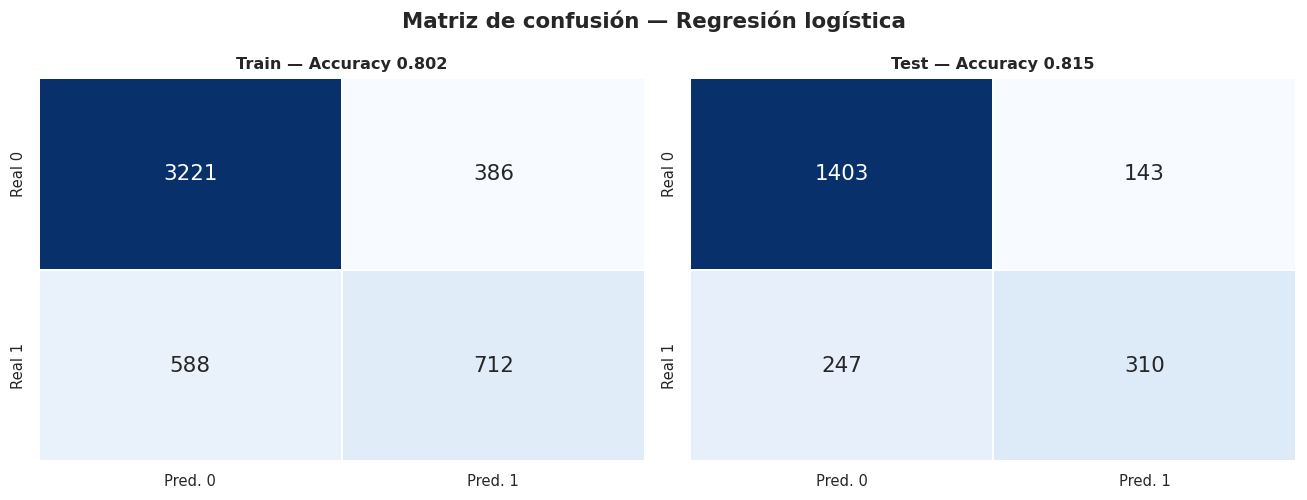

In [68]:
graficar_matrices_confusion(modelo_log, X_train, y_train, X_test, y_test,
                            nombre="Regresión logística")

In [69]:
print("REPORTE DE CLASIFICACIÓN — TEST\n")
print(classification_report(y_test, modelo_log.predict(X_test),
                            target_names=["No fuga", "Fuga"]))

REPORTE DE CLASIFICACIÓN — TEST

              precision    recall  f1-score   support

     No fuga       0.85      0.91      0.88      1546
        Fuga       0.68      0.56      0.61       557

    accuracy                           0.81      2103
   macro avg       0.77      0.73      0.75      2103
weighted avg       0.81      0.81      0.81      2103



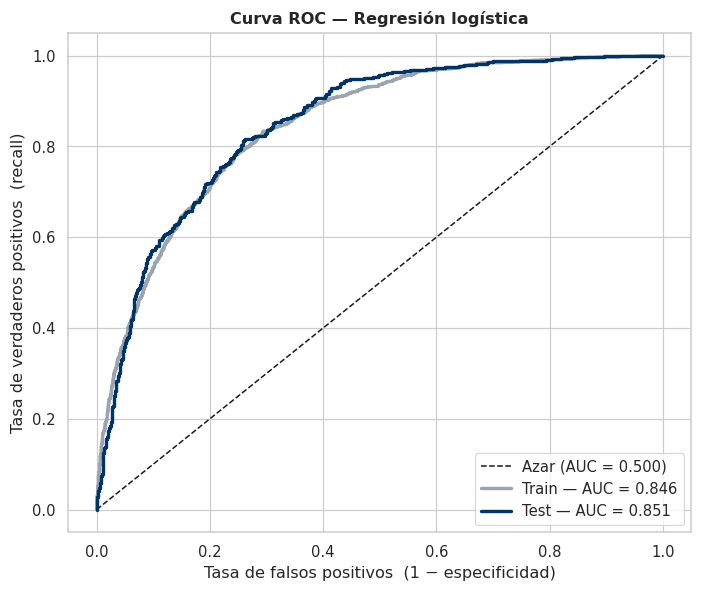

In [70]:
graficar_roc(modelo_log, X_train, y_train, X_test, y_test, nombre="Regresión logística")

### 10.4 Interpretación de los coeficientes

Como las variables están escaladas, los coeficientes son comparables entre sí y su magnitud
indica peso relativo. El signo dice la dirección: positivo aumenta la probabilidad de fuga,
negativo la reduce.

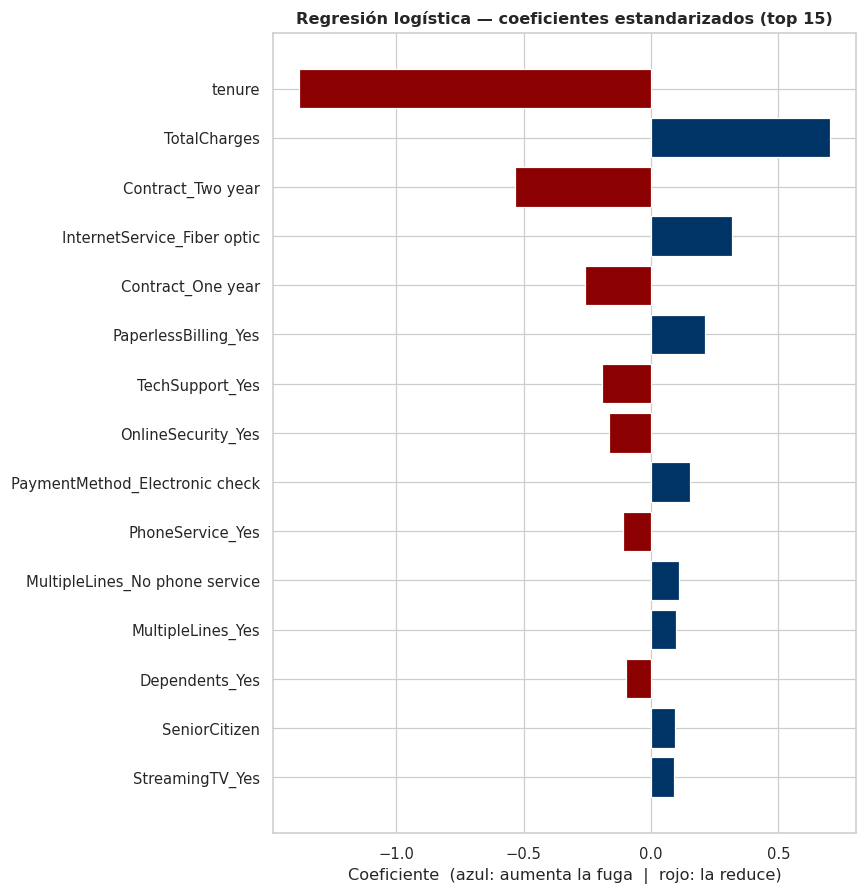

,Variable,Valor,Odds ratio
0,tenure,-1.380,0.252
1,TotalCharges,0.701,2.015
2,Contract_Two year,-0.533,0.587
3,InternetService_Fiber optic,0.319,1.376
4,Contract_One year,-0.261,0.770
5,PaperlessBilling_Yes,0.211,1.235
6,TechSupport_Yes,-0.194,0.824
7,OnlineSecurity_Yes,-0.165,0.848
8,PaymentMethod_Electronic check,0.154,1.166
9,PhoneService_Yes,-0.111,0.895


In [71]:
coefs = modelo_log.named_steps["clasificador"].coef_[0]

tabla_coefs = graficar_importancias(
    coefs, X_train.columns,
    titulo="Regresión logística — coeficientes estandarizados (top 15)",
    xlabel="Coeficiente  (azul: aumenta la fuga  |  rojo: la reduce)"
)
tabla_coefs["Odds ratio"] = np.exp(tabla_coefs["Valor"])
tabla_coefs.round(3)

**Lectura de negocio.** Se espera que el tipo de contrato (mes a mes vs. anual/2 años) y la
antigüedad (`tenure`) aparezcan entre los coeficientes más grandes, en la misma dirección que ya
anticipó el análisis bivariado de la sección 5: a menor antigüedad y contrato más corto, mayor
probabilidad de fuga.

## 11. Modelo 2 — Árbol de decisión

### 11.1 Un árbol sin restricciones: el sobreajuste en vivo

Sin límite de profundidad, el árbol sigue dividiendo hasta que cada hoja quede lo más pura
posible — en el límite, memoriza el conjunto de entrenamiento.

In [72]:
arbol_sin_podar = DecisionTreeClassifier(random_state=SEMILLA)

res_arbol_full = evaluar_modelo(arbol_sin_podar, X_train, y_train, X_test, y_test,
                                nombre="Árbol sin podar")
res_arbol_full.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Árbol sin podar,0.9980,0.9924,1.0000,0.9972,0.9962,1.0000,1.0000
Test,Árbol sin podar,0.7318,0.4942,0.5386,0.8014,0.5155,0.6697,0.3393


In [73]:
print(f"Profundidad alcanzada: {arbol_sin_podar.get_depth()}")
print(f"Número de hojas: {arbol_sin_podar.get_n_leaves()}\n")

for m in ["Accuracy", "Recall", "AUC"]:
    diagnostico_sobreajuste(res_arbol_full, metrica=m)
    print()

Profundidad alcanzada: 22
Número de hojas: 970

Accuracy       Train = 0.998   Test = 0.732   Brecha = +0.266
⚠️  SOBREAJUSTE — el modelo memorizó el train

Recall         Train = 1.000   Test = 0.539   Brecha = +0.461
⚠️  SOBREAJUSTE — el modelo memorizó el train

AUC            Train = 1.000   Test = 0.670   Brecha = +0.330
⚠️  SOBREAJUSTE — el modelo memorizó el train



Un accuracy muy alto en train frente a una caída notable en test es la firma clásica del
sobreajuste: el árbol construyó reglas a la medida de clientes puntuales del entrenamiento, que no
se sostienen frente a clientes nuevos. **Si solo se reportara el número de train, se concluiría
—equivocadamente— que el modelo es excelente.**

### 11.2 Podar el árbol

`max_depth` limita cuántas preguntas encadena el árbol y `min_samples_leaf` exige un mínimo de
clientes por hoja, impidiendo reglas construidas sobre dos o tres casos.

In [74]:
arbol = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=40,
    random_state=SEMILLA
)

res_arbol = evaluar_modelo(arbol, X_train, y_train, X_test, y_test, nombre="Árbol podado")
res_arbol.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Árbol podado,0.8005,0.6922,0.4446,0.9287,0.5415,0.8436,0.6872
Test,Árbol podado,0.7922,0.6685,0.4273,0.9237,0.5214,0.8357,0.6713


In [75]:
diagnostico_sobreajuste(res_arbol, metrica="Accuracy")

Accuracy       Train = 0.800   Test = 0.792   Brecha = +0.008
✅ Generaliza bien — la brecha es aceptable


np.float64(0.008287480470076769)

### 11.3 Visualizar las reglas

La razón por la que un árbol sigue siendo útil aunque no sea el más preciso: se puede leer y
explicar a un área comercial sin tecnicismos.

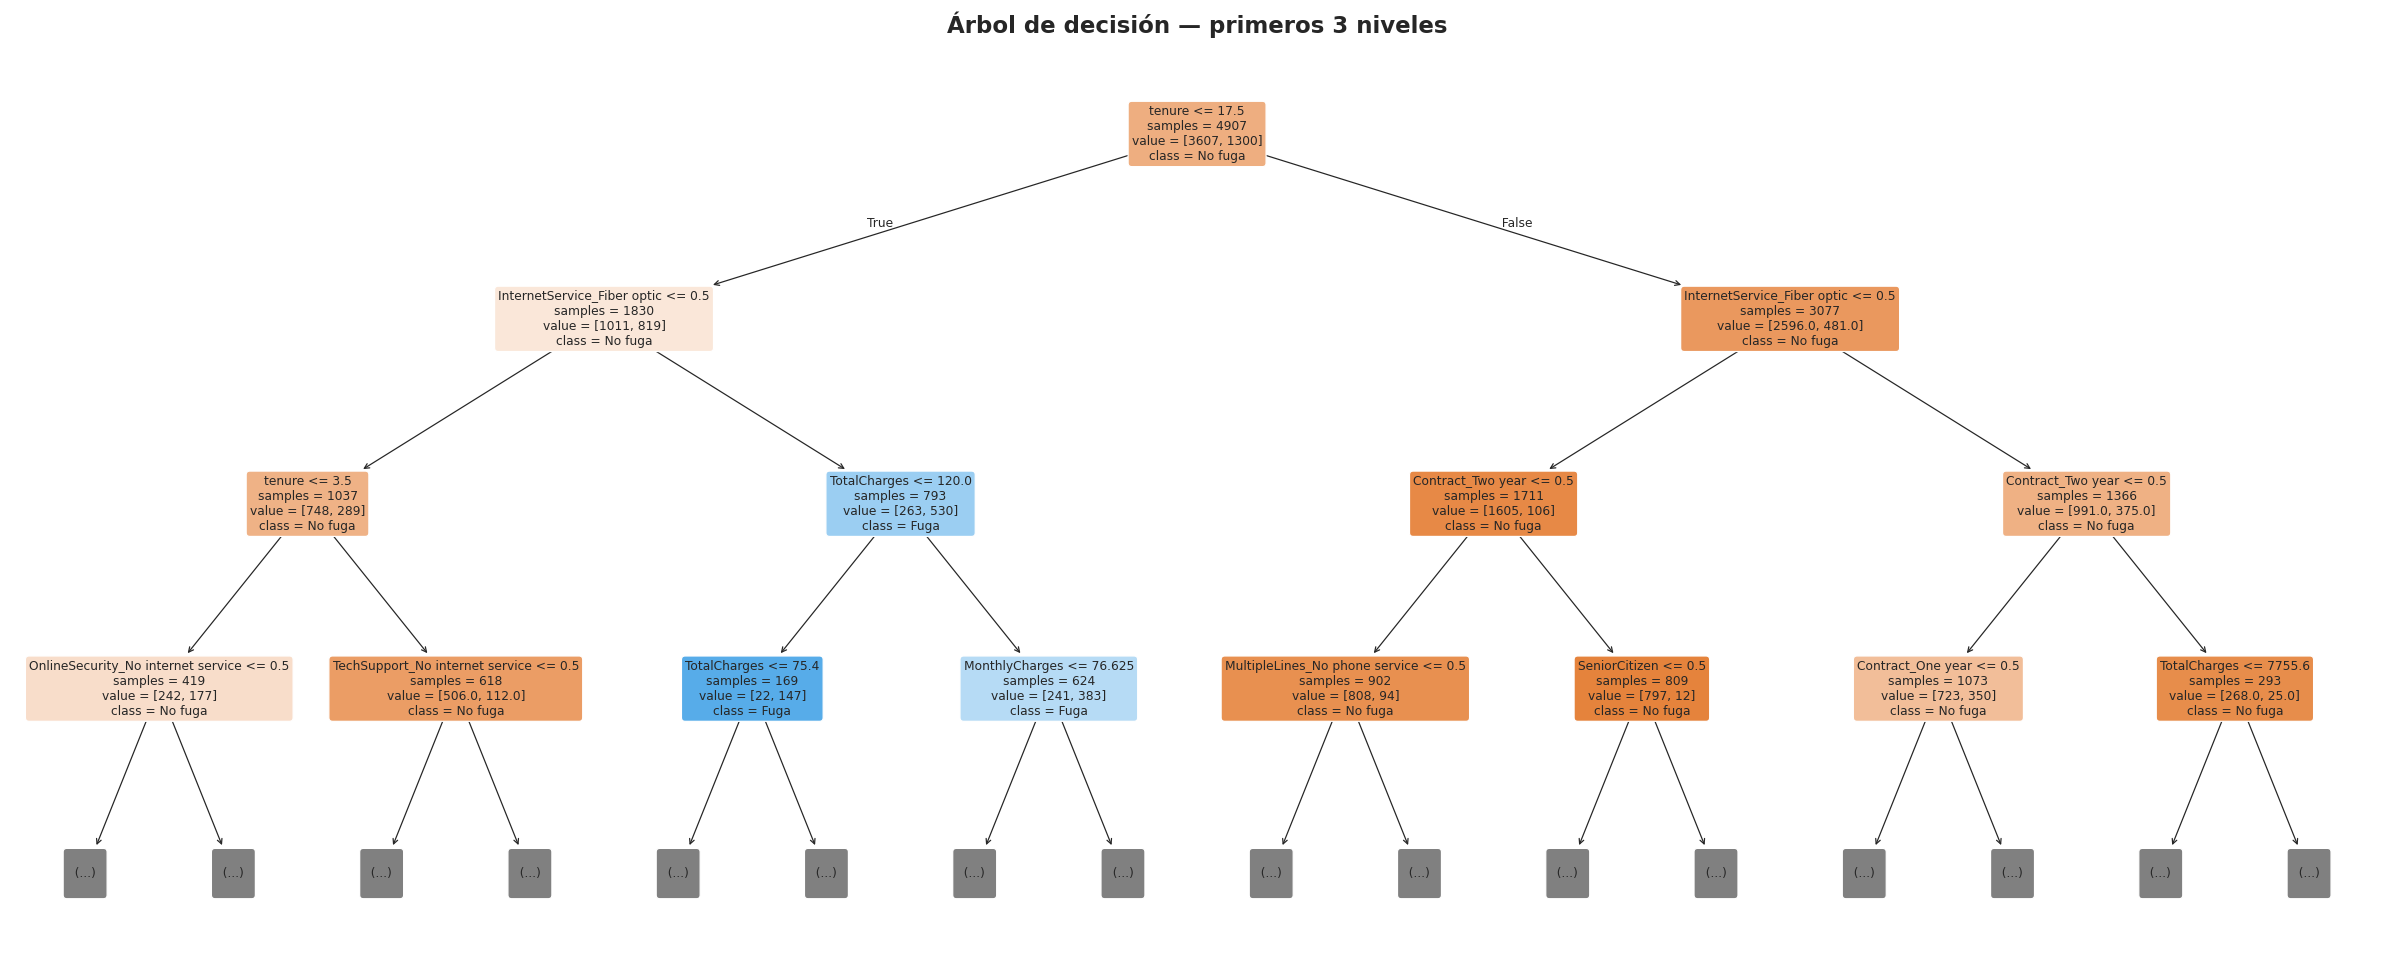

In [76]:
plt.figure(figsize=(22, 9))
plot_tree(arbol,
          feature_names=list(X_train.columns),
          class_names=["No fuga", "Fuga"],
          filled=True, rounded=True, fontsize=8, max_depth=3, impurity=False)
plt.title("Árbol de decisión — primeros 3 niveles", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 12. Modelo 3 — Random Forest

Entrena muchos árboles sobre muestras distintas de los datos y promedia sus votos: un árbol
individual sobreajusta, pero el promedio de muchos árboles que sobreajustan de formas distintas
cancela buena parte de ese error.

In [88]:
modelo_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=10,
    random_state=SEMILLA,
    n_jobs=-1
)

res_rf = evaluar_modelo(modelo_rf, X_train, y_train, X_test, y_test, nombre="Random Forest")
res_rf.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Random Forest,0.8017,0.7067,0.4300,0.9357,0.5347,0.8543,0.7087
Test,Random Forest,0.7960,0.6939,0.4111,0.9347,0.5163,0.8490,0.6980


In [82]:
for m in ["Accuracy", "Recall", "AUC"]:
    diagnostico_sobreajuste(res_rf, metrica=m)
    print()

Accuracy       Train = 0.821   Test = 0.804   Brecha = +0.017
✅ Generaliza bien — la brecha es aceptable

Recall         Train = 0.510   Test = 0.472   Brecha = +0.038
✅ Generaliza bien — la brecha es aceptable

AUC            Train = 0.881   Test = 0.853   Brecha = +0.027
✅ Generaliza bien — la brecha es aceptable



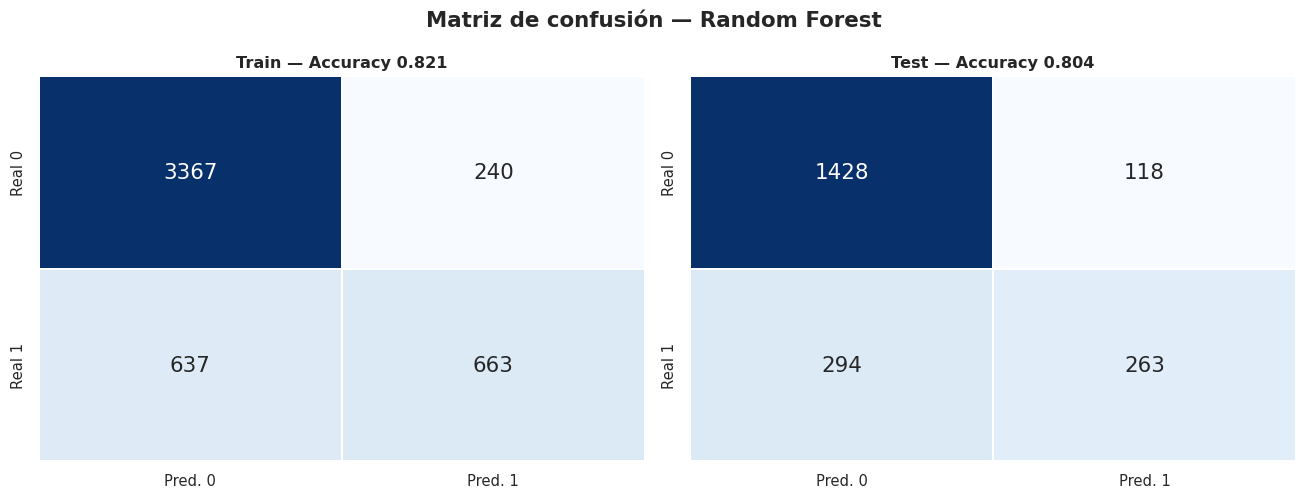

In [83]:
graficar_matrices_confusion(modelo_rf, X_train, y_train, X_test, y_test, nombre="Random Forest")

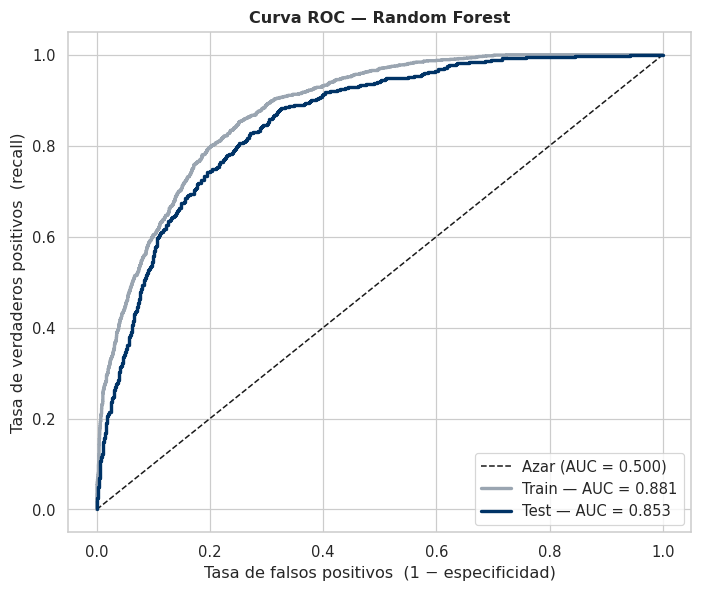

In [84]:
graficar_roc(modelo_rf, X_train, y_train, X_test, y_test, nombre="Random Forest")

### 12.1 Importancia de las variables

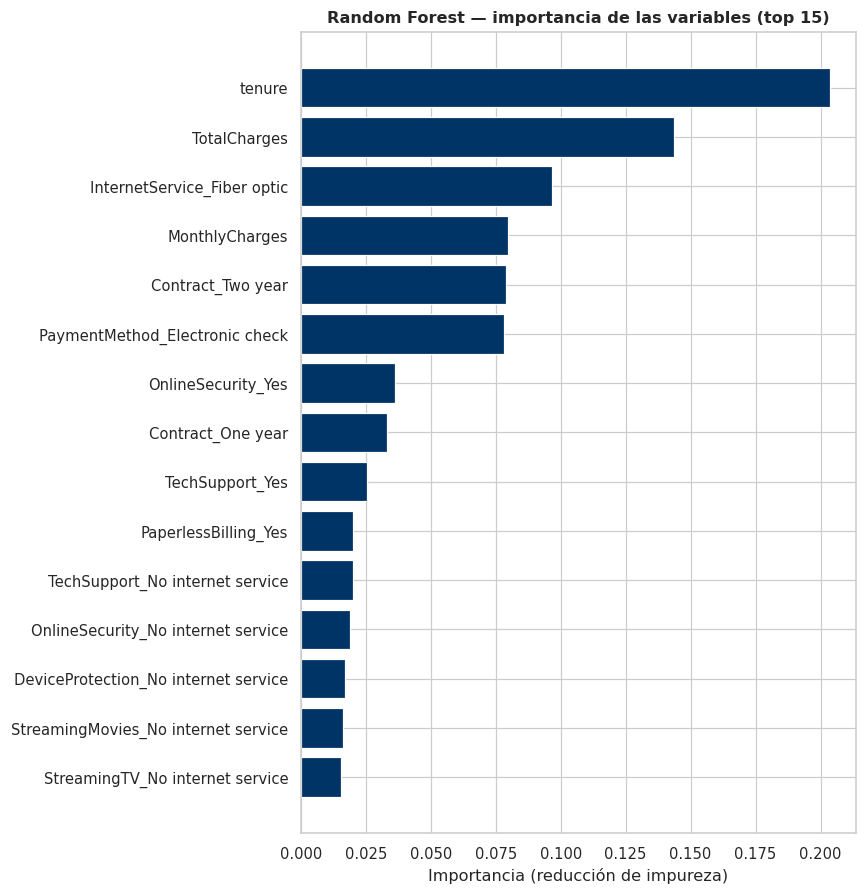

,Variable,Valor
0,tenure,0.2035
1,TotalCharges,0.1438
2,InternetService_Fiber optic,0.0965
3,MonthlyCharges,0.0799
4,Contract_Two year,0.0790
5,PaymentMethod_Electronic check,0.0781
6,OnlineSecurity_Yes,0.0361
7,Contract_One year,0.0330
8,TechSupport_Yes,0.0256
9,PaperlessBilling_Yes,0.0200


In [85]:
tabla_imp = graficar_importancias(
    modelo_rf.feature_importances_, X_train.columns,
    titulo="Random Forest — importancia de las variables (top 15)",
    xlabel="Importancia (reducción de impureza)"
)
tabla_imp.round(4)

A diferencia de los coeficientes de la regresión logística, la importancia de Random Forest
indica *cuánto* aporta una variable, pero no *en qué dirección* — para la dirección hay que volver
a los coeficientes de la sección 10.4 o al análisis bivariado de la sección 5.

### 12.2 Teoría en corto — GridSearchCV vs. RandomizedSearchCV

- **GridSearchCV**: prueba **todas** las combinaciones de una cuadrícula fija. Exhaustivo y
  determinístico, pero el costo crece exponencial ($m^n$) con el número de hiperparámetros.
- **RandomizedSearchCV**: muestrea `n_iter` combinaciones al azar de un rango/distribución. No
  garantiza el óptimo exacto, pero cubre espacios mucho más grandes a una fracción del costo.
- **Práctica recomendada**: primero `RandomizedSearchCV` sobre un rango amplio, para ubicar la
  zona prometedora; después `GridSearchCV`, ya acotado a esa zona, para afinar. Es el orden que
  se sigue a continuación.

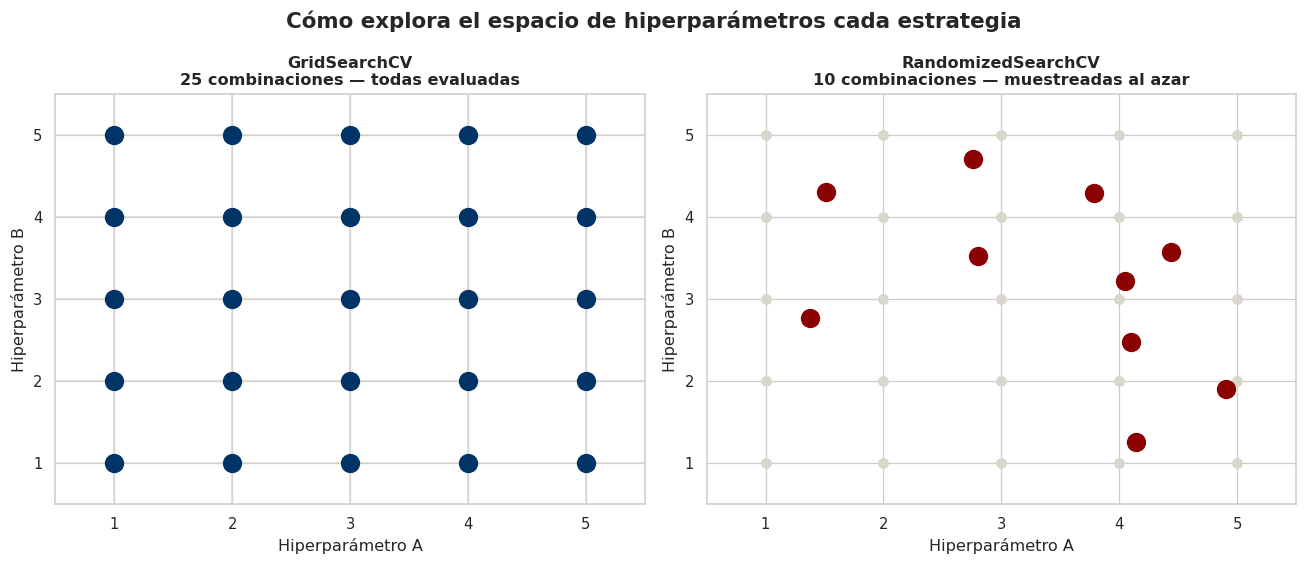

In [86]:
# Ilustración conceptual (no usa el modelo real): cómo recorre cada estrategia
# el espacio de dos hiperparámetros cualquiera.
rng = np.random.default_rng(SEMILLA)

valores_x = [1, 2, 3, 4, 5]
valores_y = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

gx, gy = np.meshgrid(valores_x, valores_y)
axes[0].scatter(gx, gy, s=140, color="#003366", zorder=3)
for x in valores_x:
    axes[0].axvline(x, color="#D9D6CC", lw=1, zorder=1)
for y in valores_y:
    axes[0].axhline(y, color="#D9D6CC", lw=1, zorder=1)
axes[0].set_title(f"GridSearchCV\n{len(valores_x) * len(valores_y)} combinaciones — todas evaluadas",
                   fontweight="bold")

n_iter_ilustracion = 10
rx = rng.uniform(min(valores_x), max(valores_x), n_iter_ilustracion)
ry = rng.uniform(min(valores_y), max(valores_y), n_iter_ilustracion)
axes[1].scatter(gx, gy, s=40, color="#D9D6CC", zorder=1)
axes[1].scatter(rx, ry, s=140, color="#8B0000", zorder=3)
axes[1].set_title(f"RandomizedSearchCV\n{n_iter_ilustracion} combinaciones — muestreadas al azar",
                   fontweight="bold")

for ax in axes:
    ax.set_xlabel("Hiperparámetro A"); ax.set_ylabel("Hiperparámetro B")
    ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5)

fig.suptitle("Cómo explora el espacio de hiperparámetros cada estrategia", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 12.3 Primero, `RandomizedSearchCV` — explorar un rango amplio, rápido

Se arranca por aquí, como dice la práctica recomendada: un rango amplio de hiperparámetros,
pocas iteraciones (`n_iter=15`), para ubicar rápido una zona prometedora sin pagar el costo de
una cuadrícula exhaustiva.

In [89]:
import time
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

distribuciones = {
    "n_estimators":     randint(80, 500),
    "max_depth":        randint(3, 20),
    "min_samples_leaf": randint(1, 40),
    "max_features":     ["sqrt", "log2", 0.3, 0.5, 0.7],
}
N_ITER = 15   # pocas iteraciones → resultado en segundos

busqueda_rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=SEMILLA),
    param_distributions=distribuciones,
    n_iter=N_ITER,
    scoring="roc_auc",
    cv=3,
    random_state=SEMILLA,
    n_jobs=-1,
)

inicio = time.time()
busqueda_rf_random.fit(X_train, y_train)
tiempo_random = time.time() - inicio

print(f"Combinaciones probadas: {N_ITER}")
print(f"Tiempo total: {tiempo_random:.1f} s")
print(f"Mejor AUC promedio en validación cruzada (train): {busqueda_rf_random.best_score_:.4f}")
print(f"Mejores hiperparámetros: {busqueda_rf_random.best_params_}")

Combinaciones probadas: 15
Tiempo total: 79.1 s
Mejor AUC promedio en validación cruzada (train): 0.8419
Mejores hiperparámetros: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 14, 'n_estimators': 321}


### 12.4 Random Forest (RandomizedSearchCV) — train vs. test

In [90]:
modelo_rf_random = busqueda_rf_random.best_estimator_

res_rf_random = evaluar_modelo(modelo_rf_random, X_train, y_train, X_test, y_test,
                               nombre="Random Forest (RandomizedSearchCV)", entrenar=False)
res_rf_random.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Random Forest (RandomizedSearchCV),0.8056,0.7060,0.4562,0.9315,0.5542,0.8614,0.7228
Test,Random Forest (RandomizedSearchCV),0.7984,0.6852,0.4417,0.9269,0.5371,0.8512,0.7023


### 12.5 Después, `GridSearchCV` — afinar alrededor de esa zona

En vez de una cuadrícula amplia y lenta, se construye una cuadrícula **pequeña**, centrada en lo
que ya encontró `RandomizedSearchCV`: un paso hacia arriba y hacia abajo en `n_estimators` y
`max_depth`, dejando `min_samples_leaf` y `max_features` fijos en su mejor valor. Con esto,
`GridSearchCV` deja de ser lento — son pocas combinaciones porque ya se sabe dónde mirar.

In [91]:
from sklearn.model_selection import GridSearchCV

base = busqueda_rf_random.best_params_

n_est_base = base["n_estimators"]
depth_base = base["max_depth"]

grilla = {
    "n_estimators":     sorted({max(50, n_est_base - 100), n_est_base, n_est_base + 100}),
    "max_depth":         sorted({max(3, depth_base - 2), depth_base, depth_base + 2}),
    "min_samples_leaf":  [base["min_samples_leaf"]],
    "max_features":      [base["max_features"]],
}
print("Cuadrícula (acotada por el resultado de RandomizedSearchCV):", grilla)

busqueda_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=SEMILLA),
    param_grid=grilla,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
)

inicio = time.time()
busqueda_rf.fit(X_train, y_train)
tiempo_grid = time.time() - inicio

combinaciones_grid = len(busqueda_rf.cv_results_["params"])
print(f"\nCombinaciones probadas: {combinaciones_grid}")
print(f"Tiempo total: {tiempo_grid:.1f} s")
print(f"Mejor AUC promedio en validación cruzada (train): {busqueda_rf.best_score_:.4f}")
print(f"Mejores hiperparámetros: {busqueda_rf.best_params_}")

Cuadrícula (acotada por el resultado de RandomizedSearchCV): {'n_estimators': [221, 321, 421], 'max_depth': [4, 6, 8], 'min_samples_leaf': [14], 'max_features': ['sqrt']}

Combinaciones probadas: 9
Tiempo total: 28.3 s
Mejor AUC promedio en validación cruzada (train): 0.8431
Mejores hiperparámetros: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 14, 'n_estimators': 321}


### 12.6 Random Forest (GridSearchCV afinado) — train vs. test

In [92]:
modelo_rf_grid = busqueda_rf.best_estimator_

res_rf_grid = evaluar_modelo(modelo_rf_grid, X_train, y_train, X_test, y_test,
                             nombre="Random Forest (GridSearchCV)", entrenar=False)
res_rf_grid.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Random Forest (GridSearchCV),0.8174,0.7196,0.5092,0.9285,0.5964,0.8753,0.7505
Test,Random Forest (GridSearchCV),0.8017,0.6842,0.4668,0.9224,0.5550,0.8528,0.7056


In [93]:
for m in ["Accuracy", "Recall", "AUC"]:
    diagnostico_sobreajuste(res_rf_grid, metrica=m)
    print()

Accuracy       Train = 0.817   Test = 0.802   Brecha = +0.016
✅ Generaliza bien — la brecha es aceptable

Recall         Train = 0.509   Test = 0.467   Brecha = +0.042
✅ Generaliza bien — la brecha es aceptable

AUC            Train = 0.875   Test = 0.853   Brecha = +0.022
✅ Generaliza bien — la brecha es aceptable



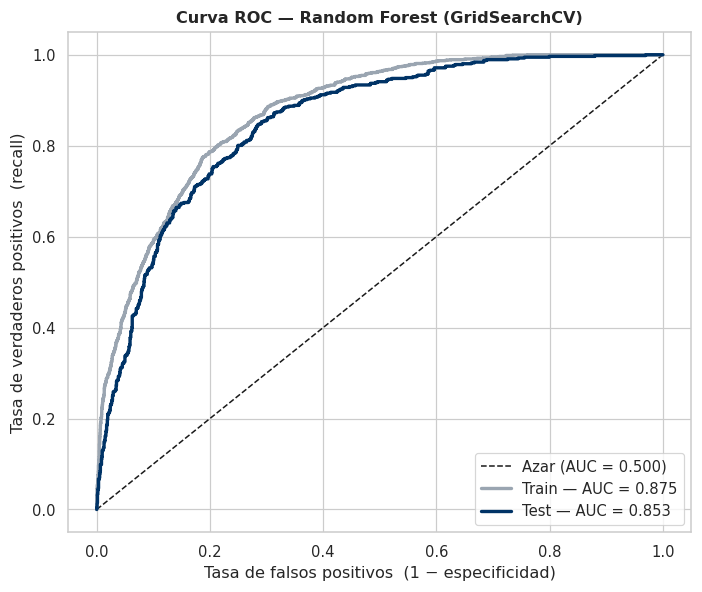

In [94]:
graficar_roc(modelo_rf_grid, X_train, y_train, X_test, y_test,
             nombre="Random Forest (GridSearchCV)")

### 12.7 Las dos estrategias, una al lado de la otra

In [95]:
tabla_busqueda = pd.DataFrame({
    "Estrategia":               ["RandomizedSearchCV (paso 1)", "GridSearchCV (paso 2, afinado)"],
    "Combinaciones evaluadas":  [N_ITER, combinaciones_grid],
    "Tiempo (s)":               [round(tiempo_random, 1), round(tiempo_grid, 1)],
    "Mejor AUC (val. cruzada)": [busqueda_rf_random.best_score_, busqueda_rf.best_score_],
    "AUC en test":              [res_rf_random.loc["Test", "AUC"], res_rf_grid.loc["Test", "AUC"]],
})
tabla_busqueda.round(4)

,Estrategia,Combinaciones evaluadas,Tiempo (s),Mejor AUC (val. cruzada),AUC en test
0,RandomizedSearchCV (paso 1),15,79.1,0.8419,0.8512
1,"GridSearchCV (paso 2, afinado)",9,28.3,0.8431,0.8528


**Lectura de esta tabla.** `RandomizedSearchCV` no necesitó recorrer una cuadrícula completa para
llegar cerca de un buen resultado; `GridSearchCV`, después, solo tuvo que confirmar y ajustar
fino sobre esa zona — por eso ambos pasos juntos siguen siendo rápidos, en vez de pagar el costo
de una cuadrícula amplia desde el inicio. El modelo que se usa de aquí en adelante es
`modelo_rf_grid`, el resultado final de ese proceso en dos pasos.

## SHAP (Explicaciones Aditivas de SHAP) en Random Forest — Resumen rápido

- **Qué es SHAP**: método basado en valores de Shapley que explica cuánto aporta cada variable a
  una predicción.
- **Por qué usarlo**: entrega interpretabilidad **global** (qué variables importan en promedio) y
  **local** (por qué una instancia tuvo cierta predicción).
- **TreeSHAP**: versión eficiente para modelos de árboles; calcula contribuciones sin explotar el
  costo computacional.
- **Lectura de gráficos**:
    - *Summary plot*: ranking de importancia y dirección del efecto.
    - *Dependence plot*: relación de una variable con su contribución y posibles interacciones.
    - *Force/Waterfall*: desglosan una predicción individual (qué empuja arriba/abajo).
- **Usos típicos**: selección de variables, detección de sesgos, explicación a negocio y
  auditoría de modelos.

A diferencia de `feature_importances_` de la sección 12.1 — que solo dice *cuánto* pesa cada
variable en promedio — SHAP dice además **en qué dirección** empuja cada variable, cliente por
cliente. Se aplica sobre `modelo_rf_grid`, el Random Forest elegido en la sección 12.7.

In [96]:
# Importa las bibliotecas que necesitarás
import shap

# TreeExplainer es la versión eficiente de SHAP para modelos de árboles (Random Forest, XGBoost, etc.)
explainer = shap.TreeExplainer(modelo_rf_grid)

### Valores SHAP sobre una muestra de test

Calcular SHAP para las ~2 100 filas de test completo es más lento de lo necesario para una
primera lectura — una muestra de 300 clientes ya es suficiente para ver los patrones globales.
`shap_values` devuelve un valor por variable, por cliente y por clase; como interesa explicar la
**fuga** (`Churn = 1`), se toma esa clase con `[:, :, 1]`.

In [97]:
X_muestra_shap = X_test.sample(300, random_state=SEMILLA)

shap_values = explainer.shap_values(X_muestra_shap)
shap_values_fuga = shap_values[:, :, 1]   # contribución hacia la clase "Fuga"

print(f"shap_values_fuga → {shap_values_fuga.shape[0]} clientes × {shap_values_fuga.shape[1]} variables")

shap_values_fuga → 300 clientes × 30 variables


### Summary plot — ranking global de importancia y dirección

Cada punto es un cliente. La posición en el eje horizontal es su contribución SHAP a la
probabilidad de fuga; el color indica si esa variable, para ese cliente, tuvo un valor alto (rojo)
o bajo (azul). Las variables están ordenadas de la más a la menos influyente en promedio.

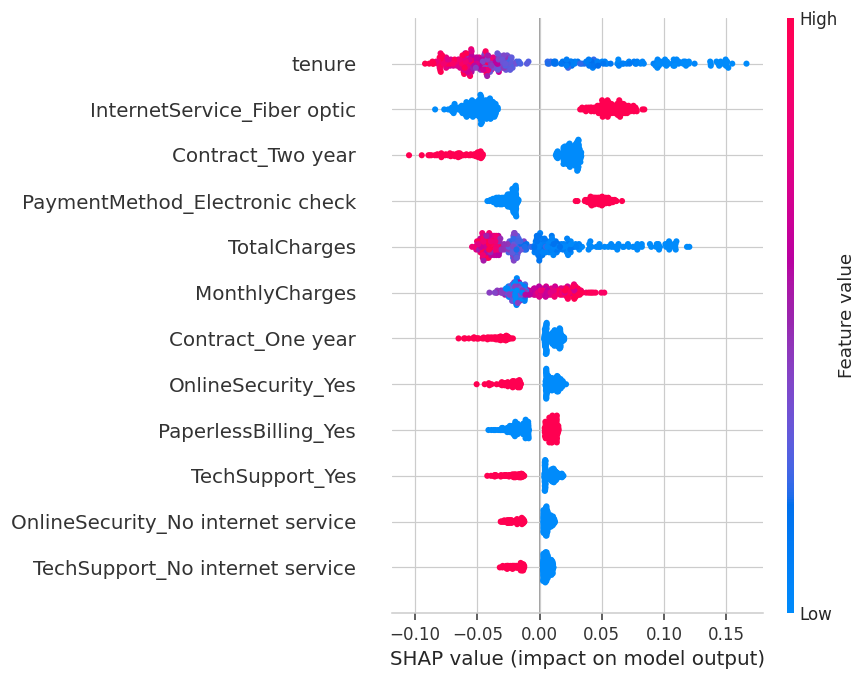

In [98]:
shap.summary_plot(shap_values_fuga, X_muestra_shap, max_display=12, show=False)
plt.tight_layout()
plt.show()

### Dependence plot — cómo pesa una variable en concreto

Se toma la variable más influyente del summary plot (`tenure`, la antigüedad) y se observa cómo
cambia su contribución SHAP a medida que cambia su valor — y si esa relación depende de otra
variable (el color marca la segunda variable con más interacción).

Variable más influyente en esta muestra: tenure


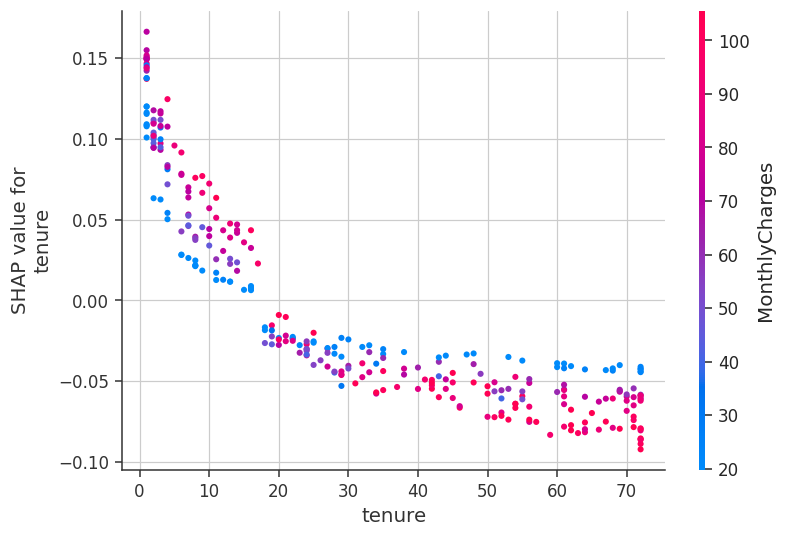

In [99]:
variable_top = X_muestra_shap.columns[np.argsort(-np.abs(shap_values_fuga).mean(0))[0]]
print(f"Variable más influyente en esta muestra: {variable_top}")

shap.dependence_plot(variable_top, shap_values_fuga, X_muestra_shap, show=False)
plt.tight_layout()
plt.show()

### Waterfall — por qué un cliente puntual tiene el score que tiene

El summary y el dependence plot son lectura **global** (todos los clientes a la vez). El
waterfall es lectura **local**: para un cliente en particular, qué variables empujaron su
probabilidad de fuga hacia arriba (rojo) o hacia abajo (azul) desde el valor base del modelo.

In [100]:
X_muestra_shap.iloc[:5]

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1777,0,28,54.90,1505.15,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0
6676,0,41,94.30,3893.60,0,1,1,1,0,1,1,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0
6195,0,4,72.20,305.55,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3554,0,7,71.05,472.65,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
5430,0,10,72.15,794.25,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0


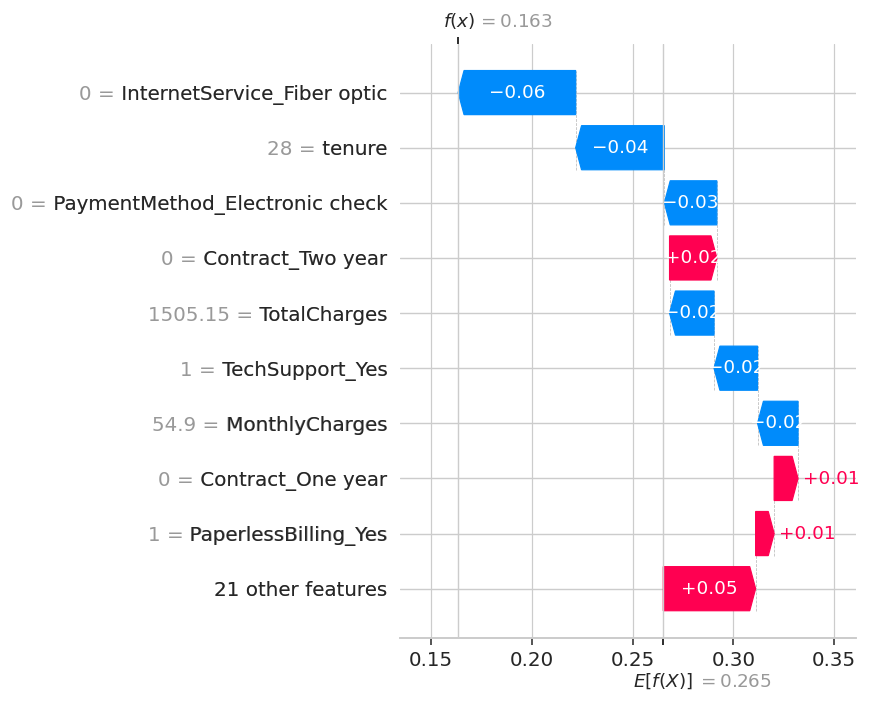

In [101]:
explicacion = explainer(X_muestra_shap.iloc[:5])   # Explanation con las 5 primeras filas de la muestra
cliente_idx = 0

shap.plots.waterfall(explicacion[cliente_idx, :, 1], show=False)
plt.tight_layout()
plt.show()

**Lectura de negocio.** El summary plot suele confirmar lo que ya mostraron los coeficientes de
la regresión logística (sección 10.4) y la importancia del Random Forest (sección 12.1) —
antigüedad, tipo de contrato y cargos concentran la mayor parte de la contribución— pero con dos
cosas de más: la **dirección** exacta para cada cliente (no solo en promedio) y la posibilidad de
explicar **un cliente puntual** al equipo de retención ("a este cliente el modelo lo marcó en
riesgo principalmente por X e Y"), algo que ni los coeficientes ni `feature_importances_` permiten
hacer por sí solos.

## 13. Comparación de los tres modelos

Un modelo no se elige por su número más alto, sino por el equilibrio entre desempeño en test,
brecha respecto de train, e interpretabilidad.

In [103]:
comparacion = pd.concat([res_log, res_arbol_full, res_arbol, res_rf, res_rf_grid])
comparacion = comparacion.reset_index().set_index(["Modelo", "Partición"])
comparacion.round(4)

Accuracy  Precision  Recall  \
Modelo                       Partición                                
Regresión logística          Train        0.8015     0.6485  0.5477   
                             Test         0.8146     0.6843  0.5566   
Árbol sin podar              Train        0.9980     0.9924  1.0000   
                             Test         0.7318     0.4942  0.5386   
Árbol podado                 Train        0.8005     0.6922  0.4446   
                             Test         0.7922     0.6685  0.4273   
Random Forest                Train        0.8017     0.7067  0.4300   
                             Test         0.7960     0.6939  0.4111   
Random Forest (GridSearchCV) Train        0.8174     0.7196  0.5092   
                             Test         0.8017     0.6842  0.4668   

                                        Especificidad      F1     AUC    Gini  
Modelo                       Partición                                         
Regresión logística          Train             0.8930  0.5938  0.8457  0.6914  
                             Test              0.9075  0.6139  0.8511  0.7023  
Árbol sin podar              Train             0.9972  0.9962  1.0000  1.0000  
                             Test              0.8014  0.5155  0.6697  0.3393  
Árbol podado                 Train             0.9287  0.5415  0.8436  0.6872  
                             Test              0.9237  0.5214  0.8357  0.6713  
Random Forest                Train             0.9357  0.5347  0.8543  0.7087  
                             Test              0.9347  0.5163  0.8490  0.6980  
Random Forest (GridSearchCV) Train             0.9285  0.5964  0.8753  0.7505  
                             Test              0.9224  0.5550  0.8528  0.7056

In [104]:
brechas = (comparacion.reset_index()
           .pivot(index="Modelo", columns="Partición", values=["Accuracy", "AUC"]))

resumen = pd.DataFrame({
    "Accuracy Train": brechas[("Accuracy", "Train")],
    "Accuracy Test":  brechas[("Accuracy", "Test")],
    "Brecha Acc":     brechas[("Accuracy", "Train")] - brechas[("Accuracy", "Test")],
    "AUC Test":       brechas[("AUC", "Test")],
    "Gini Test":      2 * brechas[("AUC", "Test")] - 1,
}).sort_values("AUC Test", ascending=False)

resumen.round(4)

,Accuracy Train,Accuracy Test,Brecha Acc,AUC Test,Gini Test
Modelo,,,,,
Random Forest (GridSearchCV),0.8174,0.8017,0.0157,0.8528,0.7056
Regresión logística,0.8015,0.8146,-0.0130,0.8511,0.7023
Random Forest,0.8017,0.7960,0.0057,0.8490,0.6980
Árbol podado,0.8005,0.7922,0.0083,0.8357,0.6713
Árbol sin podar,0.9980,0.7318,0.2662,0.6697,0.3393


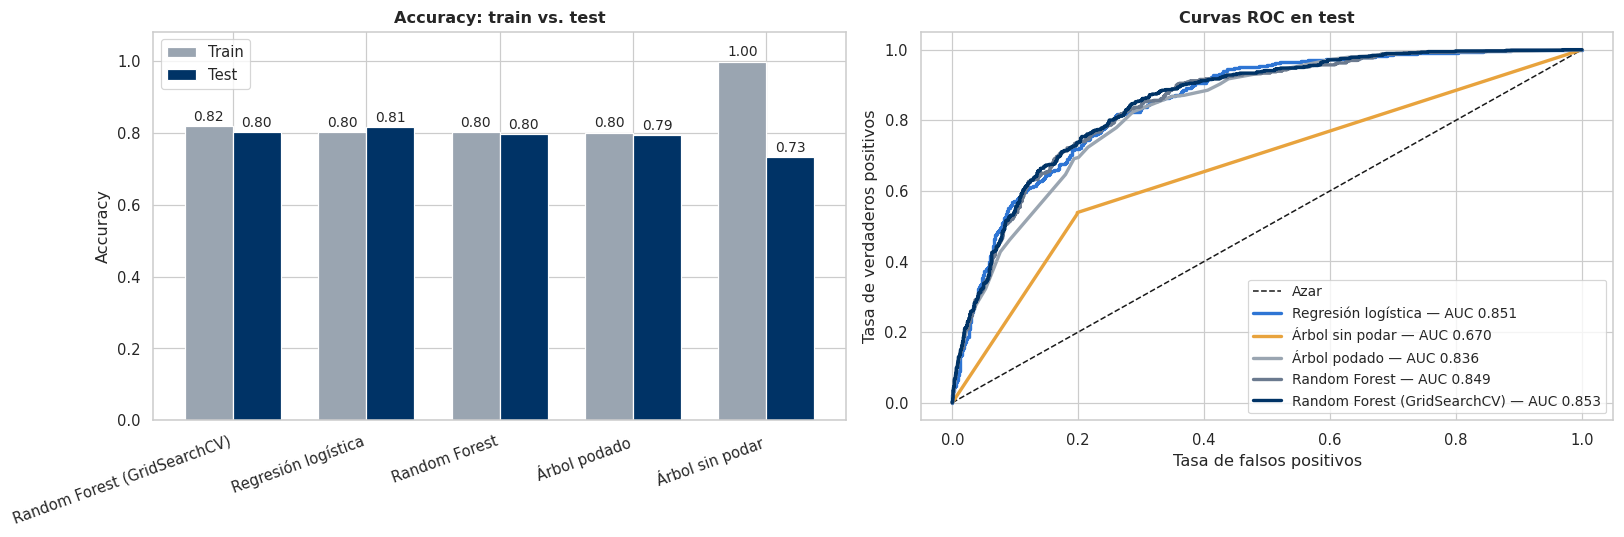

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

orden = resumen.index
x = np.arange(len(orden)); ancho = 0.36
axes[0].bar(x - ancho/2, resumen["Accuracy Train"], ancho, label="Train", color="#9AA5B1")
axes[0].bar(x + ancho/2, resumen["Accuracy Test"],  ancho, label="Test",  color="#003366")
axes[0].set_xticks(x); axes[0].set_xticklabels(orden, rotation=20, ha="right")
axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0, 1.08)
axes[0].set_title("Accuracy: train vs. test", fontweight="bold")
axes[0].legend()
for i, (tr, te) in enumerate(zip(resumen["Accuracy Train"], resumen["Accuracy Test"])):
    axes[0].text(i - ancho/2, tr + .015, f"{tr:.2f}", ha="center", fontsize=9)
    axes[0].text(i + ancho/2, te + .015, f"{te:.2f}", ha="center", fontsize=9)

axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Azar")
for (nombre, mdl), color in zip(
        [("Regresión logística", modelo_log), ("Árbol sin podar", arbol_sin_podar),
         ("Árbol podado", arbol), ("Random Forest", modelo_rf),
         ("Random Forest (GridSearchCV)", modelo_rf_grid)],
        ["#2E75D4", "#E8A33D", "#9AA5B1", "#6B7A8F", "#003366"]):
    proba = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, lw=2.2, color=color,
                 label=f"{nombre} — AUC {roc_auc_score(y_test, proba):.3f}")
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curvas ROC en test", fontweight="bold")
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

### Decisión

El árbol sin podar vuelve a mostrar por qué la comparación train-test no es un formalismo: tiene
la mayor accuracy de train de los cinco y, aun así, no es el mejor candidato en test — esa altura
en train es memoria, no aprendizaje. Entre los modelos que generalizan bien, el **Random Forest
ajustado con `GridSearchCV`** es el que se lleva a producción en lo que resta del cuaderno: su AUC
de test queda prácticamente igual al del Random Forest afinado a mano (sección 12), pero llega ahí
por búsqueda sistemática con validación cruzada en vez de prueba y error — la elección queda
respaldada por evidencia, no por intuición. La regresión logística se conserva como referencia
interpretable: pierde algunos puntos de AUC, pero explica *por qué* clasifica como clasifica, algo
valioso cuando hay que justificar una campaña de retención ante el área comercial.

## 14. El punto de corte

Hasta aquí se usó el umbral por defecto de 0.5. Pero el modelo entrega una **probabilidad**, no
una clase — el 0.5 es una decisión de negocio disfrazada de configuración técnica.

- **Umbral alto** → se marca como "en riesgo" a pocos clientes, casi todos realmente fugan.
  Alta precision, bajo recall: se dejan fugar clientes que no se detectaron.
- **Umbral bajo** → se marca a muchos clientes como "en riesgo", se captura casi toda la fuga real.
  Alto recall, baja precision: se gastan incentivos de retención en clientes que no iban a fugar.

In [106]:
proba_test = modelo_rf_grid.predict_proba(X_test)[:, 1]   # modelo elegido en la sección 13

tabla_umbral = barrido_umbral(y_test, proba_test)
tabla_umbral.round(3)

,Umbral,Contactados,TP,FP,FN,TN,Precision,Recall,F1
0,0.10,1441,536,905,21,641,0.372,0.962,0.537
1,0.15,1233,520,713,37,833,0.422,0.934,0.581
2,0.20,1076,502,574,55,972,0.467,0.901,0.615
3,0.25,928,475,453,82,1093,0.512,0.853,0.640
4,0.30,779,429,350,128,1196,0.551,0.770,0.642
5,0.35,658,392,266,165,1280,0.596,0.704,0.645
6,0.40,548,351,197,206,1349,0.641,0.630,0.635
7,0.45,466,310,156,247,1390,0.665,0.557,0.606
8,0.50,380,260,120,297,1426,0.684,0.467,0.555
9,0.55,288,199,89,358,1457,0.691,0.357,0.471


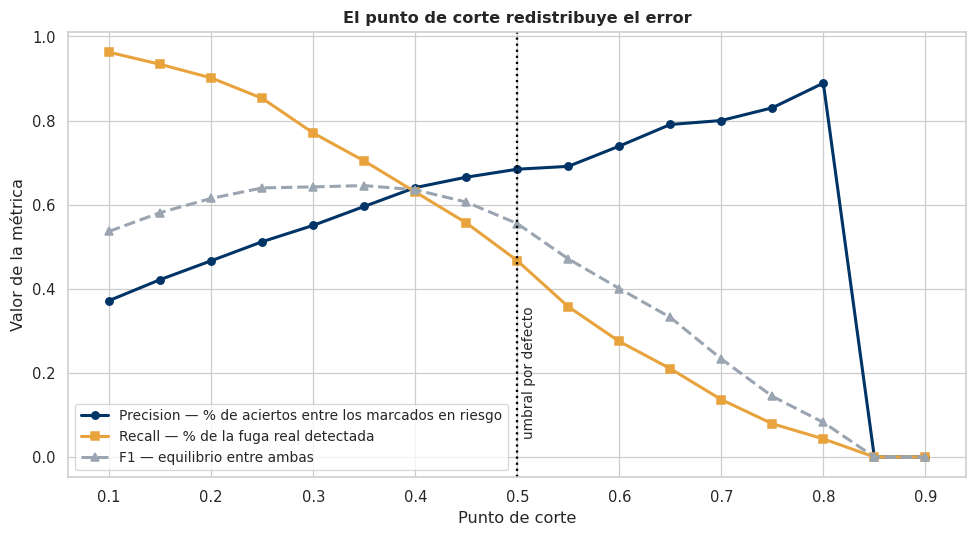

In [107]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_umbral["Umbral"], tabla_umbral["Precision"], "o-", color="#003366",
        lw=2, label="Precision — % de aciertos entre los marcados en riesgo")
ax.plot(tabla_umbral["Umbral"], tabla_umbral["Recall"], "s-", color="#E8A33D",
        lw=2, label="Recall — % de la fuga real detectada")
ax.plot(tabla_umbral["Umbral"], tabla_umbral["F1"], "^--", color="#9AA5B1",
        lw=2, label="F1 — equilibrio entre ambas")
ax.axvline(0.5, color="black", ls=":", lw=1.5)
ax.text(0.505, 0.05, "umbral por defecto", fontsize=9, rotation=90)
ax.set_xlabel("Punto de corte"); ax.set_ylabel("Valor de la métrica")
ax.set_title("El punto de corte redistribuye el error", fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Cómo pensarlo en este caso.** Igual que en Vitrina, si el equipo de retención solo puede
contactar a una cantidad limitada de clientes por semana (capacidad de la campaña, no del modelo),
el umbral deja de ser la herramienta correcta: conviene **ordenar por score y cortar donde se
acaba el presupuesto**. Eso es lo que se hace en la siguiente sección.

## 15. Del modelo a la decisión de negocio

### 15.1 Tabla de deciles

Se ordena la base de test por score de mayor a menor, se parte en diez grupos iguales y se mide la
tasa de fuga real de cada uno. El **lift** indica cuántas veces más fuga hay en ese decil respecto
de la tasa global — y por lo tanto, cuánto mejor es priorizarlo frente a elegir al azar.

In [109]:
proba_test

array([0.25227603, 0.04373706, 0.82132125, ..., 0.02122988, 0.42158604,
       0.45360447])

In [108]:
deciles = tabla_deciles(y_test, proba_test)
deciles.round(3)

,Clientes,Fugados,Tasa_fuga,Score_min,Score_max,Lift,Captura_acum_%
Decil,,,,,,,
1,211,157,0.744,0.596,0.846,2.809,28.187
2,210,130,0.619,0.474,0.596,2.337,51.526
3,210,91,0.433,0.363,0.474,1.636,67.864
4,210,68,0.324,0.281,0.363,1.223,80.072
5,210,52,0.248,0.209,0.281,0.935,89.408
6,211,22,0.104,0.139,0.209,0.394,93.357
7,210,21,0.100,0.092,0.139,0.378,97.127
8,210,11,0.052,0.046,0.092,0.198,99.102
9,210,3,0.014,0.020,0.046,0.054,99.641


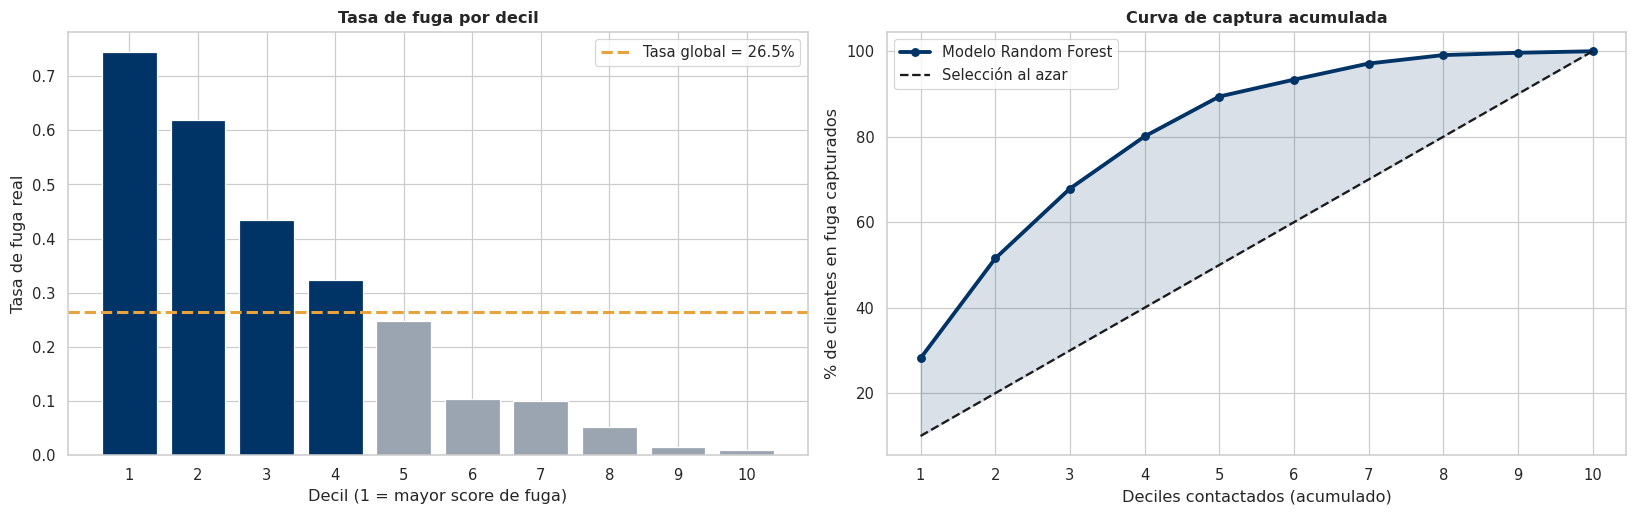

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

colores = ["#003366" if v >= 1 else "#9AA5B1" for v in deciles["Lift"]]
axes[0].bar(deciles.index, deciles["Tasa_fuga"], color=colores, edgecolor="white")
axes[0].axhline(y_test.mean(), color="#E8A33D", ls="--", lw=2,
                label=f"Tasa global = {y_test.mean():.1%}")
axes[0].set_xlabel("Decil (1 = mayor score de fuga)"); axes[0].set_ylabel("Tasa de fuga real")
axes[0].set_title("Tasa de fuga por decil", fontweight="bold")
axes[0].set_xticks(deciles.index); axes[0].legend()

axes[1].plot(deciles.index, deciles["Captura_acum_%"], "o-", color="#003366", lw=2.5,
             label="Modelo Random Forest")
axes[1].plot(deciles.index, np.arange(10, 101, 10), "k--", lw=1.5, label="Selección al azar")
axes[1].fill_between(deciles.index, np.arange(10, 101, 10),
                     deciles["Captura_acum_%"], alpha=.15, color="#003366")
axes[1].set_xlabel("Deciles contactados (acumulado)")
axes[1].set_ylabel("% de clientes en fuga capturados")
axes[1].set_title("Curva de captura acumulada", fontweight="bold")
axes[1].set_xticks(deciles.index); axes[1].legend()

plt.tight_layout()
plt.show()

### 15.2 El impacto de una campaña de retención

Supongamos que el equipo de retención puede contactar, con una oferta de retención, a un número
limitado de clientes por mes. Con ese mismo presupuesto, ¿cuántos clientes en riesgo real de fuga
alcanza el modelo frente a una lista armada al azar?

In [111]:
CAPACIDAD       = 300    # contactos mensuales disponibles para la campaña de retención
VALOR_RETENCION = 400    # margen anualizado que se preserva si un cliente en riesgo no fuga (S/)
COSTO_CONTACTO  = 25     # costo por contacto (oferta + operación), en soles

ranking = (pd.DataFrame({"score": proba_test, "fuga": y_test.values})
             .sort_values("score", ascending=False)
             .reset_index(drop=True))

seleccion  = ranking.head(CAPACIDAD)
con_modelo = int(seleccion["fuga"].sum())
al_azar    = CAPACIDAD * y_test.mean()

escenarios = pd.DataFrame({
    "Clientes en fuga real alcanzados": [al_azar, con_modelo],
    "Tasa de acierto":                  [y_test.mean(), con_modelo / CAPACIDAD],
    "Valor protegido (S/)":             [al_azar * VALOR_RETENCION, con_modelo * VALOR_RETENCION],
    "Costo campaña (S/)":               [CAPACIDAD * COSTO_CONTACTO] * 2,
}, index=["Lista al azar", "Lista del modelo"])
escenarios["Valor neto (S/)"] = (escenarios["Valor protegido (S/)"]
                                 - escenarios["Costo campaña (S/)"])

print(escenarios.to_string(float_format=lambda v: f"{v:,.2f}"))

extra = con_modelo - al_azar
print(f"\n{'─'*66}")
print(f"Con el mismo presupuesto y la misma capacidad de {CAPACIDAD} contactos:")
print(f"  · Clientes en fuga real adicionales : {extra:,.0f}")
print(f"  · Lift sobre el azar                : {con_modelo / al_azar:.2f}x")
print(f"  · Valor incremental protegido        : S/ {extra * VALOR_RETENCION:,.0f}")
print(f"{'─'*66}")

                  Clientes en fuga real alcanzados  Tasa de acierto  Valor protegido (S/)  Costo campaña (S/)  Valor neto (S/)
Lista al azar                                79.46             0.26             31,783.17                7500        24,283.17
Lista del modelo                            209.00             0.70             83,600.00                7500        76,100.00

──────────────────────────────────────────────────────────────────
Con el mismo presupuesto y la misma capacidad de 300 contactos:
  · Clientes en fuga real adicionales : 130
  · Lift sobre el azar                : 2.63x
  · Valor incremental protegido        : S/ 51,817
──────────────────────────────────────────────────────────────────


> **Advertencia metodológica.** `VALOR_RETENCION` y `COSTO_CONTACTO` son supuestos razonables para
> ilustrar el cálculo, no cifras reales de la empresa. La cifra que sí es un resultado del modelo
> —y no un supuesto— es el **lift**: cuántas veces mejor es priorizar por score frente a elegir al
> azar con la misma capacidad de contacto.

### 15.3 Scoring de la base completa

El entregable operativo: la base con su score de fuga y su decil de prioridad, lista para que el
equipo de retención la cargue en el CRM.

In [112]:
base_scoreada = df_modelo.copy()
base_scoreada["Score"]      = modelo_rf_grid.predict_proba(X)[:, 1]
base_scoreada["Prediccion"] = (base_scoreada["Score"] >= 0.5).astype(int)
base_scoreada["Decil"]      = 11 - pd.qcut(base_scoreada["Score"].rank(method="first"),
                                           10, labels=range(1, 11)).astype(int)
base_scoreada["Prioridad"]  = pd.cut(base_scoreada["Decil"], [0, 3, 6, 10],
                                     labels=["Alta", "Media", "Baja"])

base_scoreada.sort_values("Score", ascending=False).head(10)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Score,Prediccion,Decil,Prioridad
585,1,1,85.70,85.70,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0.854645,1,1,Alta
4800,1,1,94.00,94.00,1,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0.853455,1,1,Alta
1976,1,1,93.55,93.55,1,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0.853455,1,1,Alta
3380,1,1,95.10,95.10,1,1,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0.847978,1,1,Alta
6866,0,1,95.45,95.45,1,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0.847310,1,1,Alta
2745,1,1,86.05,86.05,1,1,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0.846387,1,1,Alta
1600,1,1,88.80,88.80,1,1,0,0,1,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0.845420,1,1,Alta
2577,0,1,94.60,94.60,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0.845380,1,1,Alta
3209,0,1,93.85,93.85,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0.844736,1,1,Alta
1371,1,1,79.20,79.20,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0.844417,1,1,Alta


In [113]:
resumen_prioridad = (base_scoreada
    .groupby("Prioridad", observed=True)
    .agg(Clientes=("Score", "size"),
         Score_promedio=("Score", "mean"),
         Tasa_fuga_real=(TARGET, "mean")))

print(resumen_prioridad.round(3).to_string())
print("\n→ El segmento de prioridad Alta es el que recibe la campaña de retención del próximo mes.")

           Clientes  Score_promedio  Tasa_fuga_real
Prioridad                                          
Alta           2103           0.556           0.615
Media          2103           0.249           0.222
Baja           2804           0.058           0.034

→ El segmento de prioridad Alta es el que recibe la campaña de retención del próximo mes.


> **Advertencia metodológica.** Esta tabla incluye clientes que el modelo usó para entrenar, por
> lo que su tasa de fuga observada es optimista. Sirve como entregable operativo, **no** como
> evidencia de desempeño — para eso valen únicamente las métricas de test de la sección 13.

## 16. Conclusiones

**Sobre el caso**

1. El modelo elegido para producción es el de mejor AUC en test con una brecha train-test
   contenida (ver sección 13); la regresión logística se conserva como referencia interpretable.
2. El tipo de contrato y la antigüedad del cliente concentran buena parte del poder predictivo,
   consistente con lo que ya mostraba el análisis bivariado de la sección 5.
3. Ordenar a los clientes por score de fuga y priorizar el contacto de retención por ahí, en vez
   de por criterio manual, produce un lift medible sobre elegir al azar con la misma capacidad de
   contacto (sección 15).
4. Ajustar el Random Forest en dos pasos — `RandomizedSearchCV` para ubicar la zona
   (sección 12.3) y `GridSearchCV` para afinar sobre ella (sección 12.5) — en lugar de fijar
   los hiperparámetros a mano, es el modelo que finalmente se usa para priorizar clientes.

**Sobre el método — lo que agregó esta sección frente al taller original**

5. **El EDA no basta para modelar.** Describir y explorar (secciones 1 a 8) es necesario pero no
   suficiente: para entrenar un clasificador hacía falta un paso adicional — codificar las
   variables de texto en columnas numéricas (**one-hot encoding**, sección 9.2) — que el taller
   original no llegaba a dar.
6. **Ningún indicador se interpreta solo.** El árbol sin podar fue el que mejor "aprendió" el
   train y, sin embargo, no es el mejor modelo: la brecha train-test es lo que distingue aprender
   de memorizar.
7. **El punto de corte y la capacidad de la campaña son decisiones de negocio**, no parámetros
   técnicos — el 0.5 por defecto no tiene nada de especial.

---

### Ejercicio propuesto

1. Repetir la sección 9.2 con `drop_first=False` y comparar cuántas columnas quedan. ¿Por qué la
   regresión logística es más sensible a esa elección que el árbol o el Random Forest?
2. Cambiar `SEMILLA` a otro valor y volver a correr las secciones 9 a 13. ¿Cuánto se mueven las
   métricas de test?
3. Entrenar el árbol podado con `max_depth` de 2 a 15 y graficar accuracy de train y de test contra
   la profundidad. Identificar el punto donde las curvas se separan.
4. Reemplazar Random Forest por el modelo ganador en la sección 15 y recalcular el lift con
   `CAPACIDAD = 600`. ¿El lift se mantiene igual? ¿Por qué cambia al ampliar la lista?

## 17. Aplicar el modelo a clientes nuevos

Todo lo anterior evaluó el modelo sobre datos que ya conocían su desenlace (`Churn`). En
producción, lo que llega cada semana son clientes **nuevos**, sin esa columna — y antes de
poder pedirle un score al modelo hay que pasarlos por *exactamente* la misma limpieza y
transformación que se usó para entrenar (secciones 2 y 9), no una versión aproximada.

### 17.1 Una base nueva, con los mismos campos que el CSV original (menos `Churn`)

In [114]:
clientes_nuevos = pd.read_csv("clientes_nuevos.csv")
clientes_nuevos

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,NEW-0001,Female,0,Yes,No,2,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.00,190.00
1,NEW-0002,Male,0,No,No,60,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Bank transfer (automatic),55.30,3318.00
2,NEW-0003,Female,1,Yes,Yes,14,Yes,No,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,80.10,NaN
3,NEW-0004,Male,0,No,No,8,No,No phone service,DSL,No,No,Yes,No,No,No,One year,No,Mailed check,34.20,273.60
4,NEW-0005,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15
5,NEW-0006,Male,0,Yes,Yes,48,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),105.40,5059.00


### 17.2 Replicar la limpieza (sección 2) y el one-hot encoding (sección 9.2)

Dos diferencias deliberadas frente al pipeline de entrenamiento, porque aquí el objetivo cambia
de "preparar datos para entrenar" a "no dejar a ningún cliente sin score":

- **Nulos**: en la sección 2.3 se hacía `dropna()` — perder unas pocas filas de 7 000 no afecta
  al entrenamiento. Acá no se puede descartar un cliente real solo porque le falta un dato; se
  imputa con la mediana de `train`.
- **Columnas dummy**: `pd.get_dummies` sobre una base nueva y chica no necesariamente genera las
  mismas columnas que generó sobre todo el train (puede faltarle una categoría poco frecuente, o
  sobrarle una que el modelo nunca vio). `reindex(columns=X.columns, fill_value=0)` alinea las
  columnas de `clientes_nuevos` a las que el modelo espera — sin este paso, `predict_proba`
  fallaría o, peor, fallaría silenciosamente con columnas desalineadas.

In [115]:
nuevos = clientes_nuevos.copy()

# Misma conversión de tipos que en la sección 2.1
nuevos["TotalCharges"] = pd.to_numeric(nuevos["TotalCharges"], errors="coerce")
nuevos["TotalCharges"] = nuevos["TotalCharges"].fillna(df2["TotalCharges"].median())

ids_nuevos = nuevos["customerID"]
nuevos = nuevos.drop(columns=["customerID"])

# Mismo one-hot encoding que en la sección 9.2
nuevos_dummies = pd.get_dummies(nuevos, drop_first=True, dtype=int)

# Paso crítico: alinear las columnas con las de entrenamiento (X)
nuevos_alineado = nuevos_dummies.reindex(columns=X.columns, fill_value=0)

print(f"clientes_nuevos → {nuevos_dummies.shape[1]} columnas antes de alinear")
print(f"nuevos_alineado  → {nuevos_alineado.shape[1]} columnas (igual que X: {X.shape[1]})")

clientes_nuevos → 30 columnas antes de alinear
nuevos_alineado  → 30 columnas (igual que X: 30)


In [116]:
nuevos_alineado.head(3)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,2,95.0,190.000,0,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0
1,0,60,55.3,3318.000,1,0,0,1,0,1,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,0
2,1,14,80.1,1403.875,0,1,1,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,1,0


### 17.3 Scoring con el modelo elegido (`modelo_rf_grid`)

El mismo modelo de la sección 13, sin volver a entrenar — solo se le pide `predict_proba` sobre
la base ya alineada.

In [120]:
resultado = pd.DataFrame({"customerID": ids_nuevos})
resultado["Score_fuga"] = modelo_rf_grid.predict_proba(nuevos_alineado)[:, 1]
resultado["Prediccion"] = (resultado["Score_fuga"] >= 0.4).astype(int)
resultado["Prioridad"]  = pd.cut(resultado["Score_fuga"], [-0.01, 0.3, 0.6, 1.01],
                                 labels=["Baja", "Media", "Alta"])

resultado.sort_values("Score_fuga", ascending=False).reset_index(drop=True)

,customerID,Score_fuga,Prediccion,Prioridad
0,NEW-0001,0.729702,1,Alta
1,NEW-0003,0.597449,1,Media
2,NEW-0005,0.327702,0,Media
3,NEW-0004,0.243815,0,Baja
4,NEW-0006,0.140369,0,Baja
5,NEW-0002,0.033317,0,Baja


In [121]:
resultado.head(3)

,customerID,Score_fuga,Prediccion,Prioridad
0,NEW-0001,0.729702,1,Alta
1,NEW-0002,0.033317,0,Baja
2,NEW-0003,0.597449,1,Media


In [122]:
resultado["Score_fuga_log"] = modelo_log.predict_proba(nuevos_alineado)[:, 1]

In [123]:
resultado

,customerID,Score_fuga,Prediccion,Prioridad,Score_fuga_log
0,NEW-0001,0.729702,1,Alta,0.760966
1,NEW-0002,0.033317,0,Baja,0.006701
2,NEW-0003,0.597449,1,Media,0.634919
3,NEW-0004,0.243815,0,Baja,0.271655
4,NEW-0005,0.327702,0,Media,0.174114
5,NEW-0006,0.140369,0,Baja,0.070288


Esta tabla — `customerID`, score, predicción y prioridad — es exactamente lo que se entregaría
al equipo de retención o se cargaría al CRM cada semana. La lección de fondo: el modelo nunca
recibe datos "crudos" — cualquier base nueva tiene que pasar por la misma limpieza y el mismo
one-hot encoding que el train, columna por columna, o el score que produce no es confiable.